# Quasinormal-mode perturbation theory for exterior perturbers: exact error laws and a distance-independent resummation

This notebook carries out the complete study reported in the accompanying manuscript. Every number and figure is computed here, starting from the closed-form quasinormal modes (QNMs) of a dielectric slab and the exact poles of the perturbed structure.

The system is a one-dimensional dielectric slab cavity perturbed by a thin dielectric layer placed outside it, at a distance $d$ from the cavity face. First-order QNM perturbation theory applied to such an exterior perturber gives a frequency shift that grows exponentially with $d$, because the QNM field itself grows exponentially outside the cavity. The notebook measures how well four perturbative schemes, an embedding-basis resonant-state expansion and a Lorentzian fit of the transmission reproduce the exact poles. It then derives the error of each perturbative scheme from an exact Fabry–Pérot form of the pole condition and tests the resummed scheme that this form suggests.

Running the notebook from top to bottom regenerates

* the data tables in `results/`,
* the 21 figures in `figures/`, as PDF and 600 dpi PNG files numbered as in the manuscript, and the index `figures/manifest.csv`,
* `results/summary.json`, which holds every number quoted in the manuscript.

A full run takes about two minutes on two cores of a 2.1 GHz processor. The longest steps are the 40-digit verification of the second-order error law (Sec. 10) and the large resonant-state-expansion bases (Sec. 16).

**Contents.** 1 Setup. 2 Theory. 3 The unperturbed cavity. 4 Validation of the numerical tools. 5 Exact poles of the perturbed structure. 6 Perturbative schemes on the full parameter grid. 7 Overview of the estimators. 8 Growth of the exact shift. 9 Error laws of the perturbative schemes. 10 The second-order coefficient in 40-digit arithmetic. 11 The error floor of the regularized scheme. 12 Scaling with perturbation strength. 13 Validity maps. 14 Scope: quality factor and perturber geometry. 15 Mode identity at large gaps. 16 Resonant-state expansion. 17 Summary of results.

## 1. Setup

The reusable numerical tools live in `src/`:

| module | content |
|---|---|
| `src/tmm.py` | transfer matrices, Newton pole search, pole continuation |
| `src/qnm.py` | closed-form slab QNMs and their normalized fields |
| `src/perturbation.py` | exterior overlap, naive, regularized, self-consistent and resummed shifts, second-order coefficient, error floor |
| `src/rse.py` | resonant-state expansion with a homogeneous basis slab |
| `src/lorentzian.py` | Lorentzian fit of the exact transmission |
| `src/stats.py` | straight-line fits with Newey–West standard errors |
| `src/plotting.py` | fixed-size single-panel figures with an automatic layout check |

Units: $c = 1$, lengths in units of the cavity length $L$, wavenumbers in units of $L^{-1}$. The time dependence is $e^{-i\omega t}$, so decaying modes have $\mathrm{Im}\,k < 0$.

In [1]:
import json
import pathlib
import time

import mpmath as mp
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import plotting as P
from src.lorentzian import fit_resonance
from src.perturbation import (exterior_overlap, naive_shift, pole_function, regularization_floor,
                              regularized_shift, second_order_coefficient, second_order_terms,
                              slab_background_ratio, solve_shift)
from src.qnm import slab_mode, slab_wavenumber
from src.rse import basis_wavenumbers, nearest, rse_wavenumbers
from src.stats import hac_linfit
from src.tmm import (dispersion, double_barrier, find_pole, track_pole, track_pole_adaptive,
                     transmission_reflection)

T_START = time.time()
FIGURES, RESULTS = pathlib.Path("figures"), pathlib.Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

N_B, N_R, L, LP = 1.0, 2.0 * np.pi, 1.0, 0.1      # background index, cavity index, lengths (L)
MODES, MU = (2, 4, 8), 4                          # tracked modes; production mode
DELTAS = np.logspace(-4.0, 0.0, 13)               # perturbation strengths delta
GAPS = np.concatenate([np.linspace(0.05, 2.0, 16, endpoint=False),
                       np.geomspace(2.0, 30.0, 28)])   # gaps d (L)
assert np.unique(GAPS).size == GAPS.size == 44
ROOT_TOL = 1e-12                                  # |M11| at accepted poles

C = P.COLORS
STYLE = {"exact": ("Exact pole", C["black"], None),
         "naive": ("Naive first order", C["vermillion"], "o"),
         "reg": ("Regularized first order", C["orange"], "s"),
         "sc": ("Self-consistent", C["blue"], "^"),
         "res": ("Resummed", C["green"], "D"),
         "res2": ("Resummed, second Born", C["purple"], "v")}
summary, manifest = {}, []
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)


def contrast(delta, n_r=N_R):
    # Permittivity change of the layer, delta (n_R^2 - n_B^2).
    return delta * (n_r**2 - N_B**2)


def layers(d, delta, n_r=N_R, lp=LP, sign=1.0):
    return double_barrier(d, n_r, sign * contrast(delta, n_r), L, lp, N_B)


def publish(fig, number, name, data, caption):
    # Save a figure under its manuscript number, index it, and display it with its caption.
    png = P.save(fig, FIGURES / f"fig{number:02d}_{name}")
    manifest.append({"figure": number, "file": png.stem, "data": data, "caption": caption})
    display(Markdown(f"**Fig. {number}.** {caption}"))
    display(P.preview(png))


def tex_sci(x, digits=1):
    # A number in LaTeX scientific notation, for captions.
    mantissa, exponent = f"{x:.{digits}e}".split("e")
    return rf"{mantissa}\times10^{{{int(exponent)}}}"

## 2. Theory

### 2.1 Model and conventions

We consider transverse-electric fields $E_y(x,t) = f(x)\,e^{-i\omega t}$ in nonmagnetic, nondispersive media with relative permittivity $\varepsilon(x) = n(x)^2$. With $c = 1$ the wavenumber is $k = \omega$ and

$$\partial_x^2 f + k^2\,\varepsilon(x)\,f = 0. \tag{1}$$

The cavity is a slab of index $n_R$ on $-L \le x \le 0$ in a background of index $n_B$. The perturbation is a layer of relative permittivity $n_B^2 + \Delta\varepsilon$ on $d \le x \le d + L_p$, with $\Delta\varepsilon = \delta\,(n_R^2 - n_B^2)$ and the dimensionless strength $\delta$ between $10^{-4}$ and 1. The production parameters are $n_R = 2\pi$, $n_B = 1$ and $L_p = 0.1\,L$.

A QNM is a solution of Eq. (1) that is purely outgoing, $f \propto e^{\pm i n_B k x}$ for $x \to \pm\infty$. With the time dependence $e^{-i\omega t}$ such solutions exist only at discrete complex wavenumbers $\tilde k$ with $\mathrm{Im}\,\tilde k < 0$.

### 2.2 Slab modes and their exterior growth

For the isolated slab the outgoing conditions give

$$n_R\,\tilde k_\mu L = \mu\pi + i\ln r, \qquad r = \frac{n_R - n_B}{n_R + n_B}. \tag{2}$$

All modes share the decay rate $\gamma_0 = |\mathrm{Im}\,\tilde k_\mu| = -\ln r/(n_R L)$, whereas the quality factor $Q_\mu = \mathrm{Re}\,\tilde k_\mu/(2\gamma_0)$ grows linearly with the mode index $\mu$. Outside the slab the mode continues as $f(x) = f_R\,e^{i n_B \tilde k x}$ for $x > 0$, where $f_R$ is its value at the right face. Because $\mathrm{Im}\,\tilde k < 0$ the intensity grows as $|f|^2 \propto e^{\gamma_f x}$, with the spatial rate

$$\gamma_f = 2 n_B \gamma_0 . \tag{3}$$

The growth is the spatial record of the temporal decay: the field at distance $x$ left the cavity a time $n_B x$ earlier, when the mode was stronger.

### 2.3 First-order perturbation theory: naive and regularized

With the normalization of Leung *et al.* [Phys. Rev. A **49**, 3068 (1994)], the first-order shift caused by a permittivity change $\Delta\varepsilon(x)$ is

$$\Delta k^{(1)} = -\frac{\tilde k}{2}\int \Delta\varepsilon(x)\, f(x)^2\, dx. \tag{4}$$

For the exterior layer, with the exterior field continued from the cavity face at a wavenumber $k_x$, the overlap is

$$F(k_x) = -\frac{\tilde k}{2}\,\Delta\varepsilon\, f_R^2\, e^{2 i n_B k_x d}\;\frac{e^{2 i n_B k_x L_p} - 1}{2 i n_B k_x}. \tag{5}$$

The **naive** scheme uses the QNM itself, $\Delta k_{\rm naive} = F(\tilde k)$, whose magnitude grows as $e^{\gamma_f d}$. The **regularized** scheme of Franke, Ren and Hughes [Phys. Rev. A **108**, 043502 (2023)] replaces the exterior QNM by a regularized field which, in the pole approximation used for perturbation theory, propagates with the real wavenumber $\mathrm{Re}\,\tilde k$; on this geometry it gives $\Delta k_{\rm reg} = F(\mathrm{Re}\,\tilde k)$. Two approximations are combined in that scheme: the regularization, which removes the exponential growth, and the pole approximation, which fixes the frequency at which the regularized field is evaluated. The ratio of the two first-order results is exact:

$$\frac{\Delta k_{\rm reg}}{\Delta k_{\rm naive}} = c\, e^{-\gamma_f d}, \qquad c = \frac{\tilde k\,\bigl(e^{2 i n_B \mathrm{Re}\tilde k\, L_p} - 1\bigr)}{\mathrm{Re}\,\tilde k\,\bigl(e^{2 i n_B \tilde k L_p} - 1\bigr)}, \tag{6}$$

with $c \to 1$ for a thin layer.

### 2.4 The exact pole condition in Fabry–Pérot form

In the gap $0 < x < d$ the exact field is a superposition of a right-going and a left-going wave. The cavity reflects the left-going wave with the amplitude reflection coefficient $\rho_c(k)$, referred to the plane $x = 0$, and the layer reflects the right-going wave with $\rho_p(k)$, referred to $x = d$. A source-free solution exists only if a round trip reproduces the wave:

$$1 = \rho_c(k)\,\rho_p(k)\, e^{2 i n_B k d}. \tag{7}$$

This condition is exact for any one-dimensional cavity and perturber separated by a uniform gap, and its roots are the zeros of the transfer-matrix element $M_{11}(k)$. Near a cavity mode the cavity reflection has a simple pole,

$$\rho_c(k) = \frac{R}{k - \tilde k} + \rho_{\rm bg}(k), \tag{8}$$

with $\rho_{\rm bg}$ analytic near $\tilde k$. Inserting Eq. (8) in Eq. (7) and solving for $k - \tilde k$ gives, without approximation,

$$k - \tilde k = \frac{G(k)}{1 - \alpha(k)\,G(k)}, \qquad G(k) = R\,\rho_p(k)\,e^{2 i n_B k d}, \qquad \alpha(k) = \frac{\rho_{\rm bg}(k)}{R}. \tag{9}$$

The first Born approximation of the layer reflection is $\rho_p^{(1)}(k) = \Delta\varepsilon\,(e^{2 i n_B k L_p} - 1)/(4 n_B^2)$. Agreement of Eq. (9) with Eq. (5) at first order requires $R = i n_B f_R^2$, and then

$$G(k) = \frac{k}{\tilde k}\,F(k). \tag{10}$$

The perturbative content of Eq. (9) is therefore the overlap of Eq. (5), evaluated at the shifted wavenumber, together with a single cavity property, $\alpha = \alpha(\tilde k)$, which describes the non-resonant part of the cavity reflection. For the slab, $\rho_c(k) = -r(1 - z)/(1 - r^2 z)$ with $z = e^{2 i n_R k L}$, and

$$R = \frac{i\,(1 - r^2)}{2 n_R L\, r}, \qquad \alpha = i\, n_R L\, \frac{1 + r^2}{1 - r^2}. \tag{11}$$

To obtain Eq. (11), write $u = k - \tilde k$ and $s = 2 i n_R L$. The pole condition, Eq. (2), states that $r^2 z(\tilde k) = 1$, so $r^2 z = e^{s u}$. Then $1 - r^2 z = -s u\,(1 + s u/2) + O(u^3)$ and $-r(1 - z) = (1 - r^2)/r + (s/r)\,u + O(u^2)$, and dividing gives

$$\rho_c(k) = \frac{i\,(1 - r^2)}{2 n_R L\, r}\,\frac{1}{k - \tilde k} - \frac{1 + r^2}{2 r} + O(k - \tilde k),$$

so that $\rho_{\rm bg}(\tilde k) = -(1 + r^2)/(2r)$ and $\alpha = \rho_{\rm bg}(\tilde k)/R$. Since $\rho_c$ depends on $k$ only through $z$, $\alpha$ is the same for every slab mode. A cavity-independent estimate follows from the single-resonance form of the reflection used in temporal coupled-mode theory, $\rho_c = \rho_{\rm bg}\,[1 - 2 i\gamma_1/(k - \tilde k)]$, where $\gamma_1$ is the decay rate through the port facing the perturber. Its residue is $R = -2 i \gamma_1 \rho_{\rm bg}$, so that

$$\alpha \approx \frac{i}{2\gamma_1}, \tag{12}$$

which equals $i/\gamma_0$ for a mirror-symmetric cavity.

### 2.5 Second-order error laws

Expanding Eq. (9) to second order in $\Delta\varepsilon$ gives

$$\Delta k = F(\tilde k) + a(d)\, F(\tilde k)^2 + O(\Delta\varepsilon^3), \tag{13}$$

$$a(d) = 2 i n_B d + \frac{2 i n_B L_p E}{E - 1} + \alpha + b\, e^{-2 i n_B \tilde k d}, \qquad b = \frac{1}{R}\left[\frac{4 i n_B \tilde k L_p E}{(E - 1)^2} - \frac{2}{E - 1}\right], \tag{14}$$

with $E = e^{2 i n_B \tilde k L_p}$. The four terms have distinct origins. The first two arise because the exterior propagation factor $e^{2 i n_B k d}$ and the layer factor must be evaluated at the true complex $k$ instead of $\tilde k$; the first grows linearly with $d$. The third describes multiple scattering between the layer and the non-resonant reflection of the cavity. The last is the second Born term of the layer reflection; relative to the others it decays as $e^{-\gamma_f d}$.

To derive Eqs. (13) and (14), write $\Delta k = k - \tilde k$ and split the layer reflection as $\rho_p = \rho_p^{(1)} + \rho_p^{(2)} + O(\Delta\varepsilon^3)$, so that $G = G^{(1)} + G^{(2)}$ with $G^{(1)}(k) = R\,\rho_p^{(1)}(k)\,e^{2 i n_B k d} = (k/\tilde k)\,F(k)$. Because $\Delta k = O(\Delta\varepsilon)$ and $\alpha(k) = \alpha(\tilde k) + O(\Delta k)$, Eq. (9) gives

$$\Delta k = G^{(1)}(\tilde k) + G^{(1)\prime}(\tilde k)\,\Delta k + \alpha\,G^{(1)}(\tilde k)^2 + G^{(2)}(\tilde k) + O(\Delta\varepsilon^3),$$

where $\Delta k$ may be replaced by $G^{(1)}(\tilde k) = F(\tilde k)$ in the second term. The logarithmic derivative $G^{(1)\prime}/G^{(1)} = 2 i n_B d + 2 i n_B L_p E/(E - 1)$ gives the first two terms of $a(d)$, and the third term gives $\alpha$. The exact reflection of a uniform layer of index $n_p = (n_B^2 + \Delta\varepsilon)^{1/2}$, referred to its front face, is $\rho_p = r_1(1 - E_p)/(1 - r_1^2 E_p)$ with $r_1 = (n_B - n_p)/(n_B + n_p)$ and $E_p = e^{2 i n_p k L_p}$. Its expansion to second order in $\Delta\varepsilon$ is Eq. (17) below, which gives $G^{(2)}(\tilde k) = F(\tilde k)\,\Delta\varepsilon\,[\,i \tilde k L_p E/(n_B(E - 1)) - 1/(2 n_B^2)]$. Eliminating $\Delta\varepsilon$ with $F(\tilde k) = R\,\Delta\varepsilon\,(E - 1)\,e^{2 i n_B \tilde k d}/(4 n_B^2)$ turns this into the last term, $b\,e^{-2 i n_B \tilde k d}\,F(\tilde k)^2$.

The naive scheme accounts for none of these terms: its relative error is $|a(d) F(\tilde k)|$, and its absolute error grows as $d\,e^{2\gamma_f d}$ at large $d$. The self-consistent and resummed schemes are defined by

$$\Delta k_{\rm sc} = G(\tilde k + \Delta k_{\rm sc}), \qquad \Delta k_{\rm res} = \frac{G(\tilde k + \Delta k_{\rm res})}{1 - \alpha\, G(\tilde k + \Delta k_{\rm res})}. \tag{15}$$

The self-consistent scheme evaluates the first-order expression, prefactor and exterior field, at the shifted wavenumber and reproduces the first two terms of Eq. (14); the resummed scheme adds $\alpha$ and reproduces everything except the second Born term. Their relative errors are

$$\epsilon_{\rm sc} \simeq \bigl|(\alpha + b\, e^{-2 i n_B \tilde k d})\, F(\tilde k)\bigr|, \qquad \epsilon_{\rm res} \simeq \bigl|b\, R\, \rho_p^{(1)}(\tilde k)\bigr|, \tag{16}$$

so the resummed error does not depend on $d$ and is proportional to $\delta$. Including the second Born term of the layer reflection,

$$\rho_p = \rho_p^{(1)}\left\{1 + \Delta\varepsilon\left[\frac{i k L_p\, e^{2 i n_B k L_p}}{n_B\,(e^{2 i n_B k L_p} - 1)} - \frac{1}{2 n_B^2}\right]\right\} + O(\Delta\varepsilon^3), \tag{17}$$

in $G$ removes this residual as well and leaves an error of third order. For the regularized scheme, Eq. (6) and $\Delta k \to F(\tilde k)$ for $\delta \to 0$ fix the small-strength error

$$\epsilon_{\rm reg} \to \bigl|1 - c\, e^{-\gamma_f d}\bigr|, \tag{18}$$

independent of $\delta$: the regularized scheme discards exactly the physical growth of the shift.

The exact shift itself grows as $|F(\tilde k)| \propto e^{\gamma_f d}$ as long as $|a(d)\,F| \ll 1$. When $|a(d)\,F|$ approaches unity, the perturbed cavity pole mixes with the poles of the resonator formed by the cavity and the layer, and a single-mode description no longer applies.

### 2.6 Numerical methods

* **Exact poles.** The transfer matrix of the layered structure is the ordered product of interface matrices $\bigl(\begin{smallmatrix}1 & r_{j}\\ r_{j} & 1\end{smallmatrix}\bigr)/t_{j}$ and propagation matrices $\mathrm{diag}(e^{-i n_j k t_j}, e^{i n_j k t_j})$. Its element $M_{11}(k)$ vanishes at the poles, which we locate by complex Newton iteration with a central-difference derivative until $|M_{11}| < 10^{-12}$.
* **Mode identity.** Perturbation theory expands the pole in powers of $\delta$ at fixed geometry, so the exact reference is the pole continued in $\delta$ from the unperturbed mode, separately at every gap. Each continuation step is bisected recursively until the pole moves by at most $\gamma_0/4$. Section 5 compares this definition with continuation in $d$ at fixed $\delta$ and with a minimal-loss criterion.
* **Independent checks.** The closed-form two-slab pole condition of Franke *et al.* and 50-digit Muller iteration confirm the transfer-matrix poles.
* **Schemes.** Self-consistent and resummed shifts are fixed points found by Newton iteration from the naive shift, with continuation from the neighbouring gap as a fallback.
* **Resonant-state expansion (RSE).** Following Doost, Langbein and Muljarov [Phys. Rev. A **85**, 023835 (2012)], the structure is embedded in a homogeneous basis slab that spans cavity, gap and layer, and the perturbed wavenumbers are the eigenvalues of
$$\frac{1}{k}\,c_n = \sum_m \left(\frac{\delta_{nm}}{k_n} + \frac{V_{nm}}{2 k_m}\right) c_m, \tag{19}$$
where $k_n$ are the basis wavenumbers and $V_{nm}$ the analytic overlaps of the permittivity change with the basis states.
* **Lorentzian estimator.** A Lorentzian is fitted to the exact transmission $|t(k)|^2$ within $\pm 3\gamma_0$ of the exact resonance. A fit is accepted only if halving the window moves the fitted centre by less than $1\%$ of $\gamma_0$.
* **Statistics.** Growth rates are slopes of straight-line fits to logarithms. Their residuals oscillate with the round-trip phase and are serially correlated, so we quote Newey–West standard errors with a Bartlett kernel.

## 3. The unperturbed cavity

The closed-form spectrum, Eq. (2), fixes the decay rate $\gamma_0$, the spatial growth rate $\gamma_f$ of the exterior field and, through Eq. (11), the residue $R$ and the background ratio $\alpha$. Figure 1 shows how the exterior intensity of the production mode grows with distance when the field is continued with the complex QNM wavenumber, and how it stays constant when the real part is used instead.

In [2]:
k_modes = {mu: slab_wavenumber(mu, N_R, L, N_B) for mu in MODES}
K0 = k_modes[MU]
GAMMA0 = abs(K0.imag)
GAMMA_F = 2.0 * N_B * GAMMA0
ALPHA = slab_background_ratio(N_R, L, N_B)
GAMMA_1 = GAMMA0 / 2.0      # decay rate through the port facing the perturber (mirror-symmetric slab)
ALPHA_CM = 1j / (2.0 * GAMMA_1)   # coupled-mode estimate, Eq. (12)
R_REFL = (N_R - N_B) / (N_R + N_B)
FIELD, _, _, F_RIGHT = slab_mode(MU, N_R, L, N_B, x1=-L)
RESIDUE = 1j * N_B * F_RIGHT**2

cavity = pd.DataFrame([{"mode": mu, "Re k (1/L)": k.real, "Im k (1/L)": k.imag,
                        "Q": k.real / (2.0 * abs(k.imag))} for mu, k in k_modes.items()])
display(cavity)
print(f"r = {R_REFL:.5f}, gamma_0 = {GAMMA0:.6f} 1/L, gamma_f = {GAMMA_F:.6f} 1/L, "
      f"decay length 1/gamma_f = {1 / GAMMA_F:.3f} L")
print(f"residue R = i n_B f_R^2 = {RESIDUE:.7f} 1/L; Eq. (11): "
      f"{1j * (1 - R_REFL**2) / (2 * N_R * L * R_REFL):.7f} 1/L")
print(f"alpha (Eq. 11) = {ALPHA.imag:.5f} i L; coupled-mode estimate i/gamma_0 = {ALPHA_CM.imag:.5f} i L")

summary["cavity"] = {
    "n_R": N_R, "n_B": N_B, "L_p": LP, "r": R_REFL,
    "k_modes": {str(mu): [k.real, k.imag] for mu, k in k_modes.items()},
    "Q_modes": {str(mu): k.real / (2 * abs(k.imag)) for mu, k in k_modes.items()},
    "gamma_0": GAMMA0, "gamma_f": GAMMA_F, "decay_length": 1 / GAMMA_F,
    "residue_im": RESIDUE.imag, "alpha_im": ALPHA.imag, "alpha_cm_im": ALPHA_CM.imag,
    "alpha_cm_rel_dev": abs(ALPHA_CM - ALPHA) / abs(ALPHA)}

,mode,Re k (1/L),Im k (1/L),Q
0,2,1.0,-0.05109,9.7857
1,4,2.0,-0.05109,19.5714
2,8,4.0,-0.05109,39.1428


r = 0.72539, gamma_0 = 0.051095 1/L, gamma_f = 0.102190 1/L, decay length 1/gamma_f = 9.786 L
residue R = i n_B f_R^2 = 0.0000000+0.0519772j 1/L; Eq. (11): 0.0000000+0.0519772j 1/L
alpha (Eq. 11) = 20.23921 i L; coupled-mode estimate i/gamma_0 = 19.57140 i L


**Fig. 1.** Intensity of the $\mu = 4$ slab mode ($n_R = 2\pi$, $Q = 19.57$), normalized to its value at the right cavity face. Outside the cavity the QNM intensity grows as $e^{\gamma_f x}$ with $\gamma_f = 0.102\,L^{-1}$; continued with the real wavenumber it stays constant. The shaded bands mark the cavity and a perturbing layer at $d = 8L$.

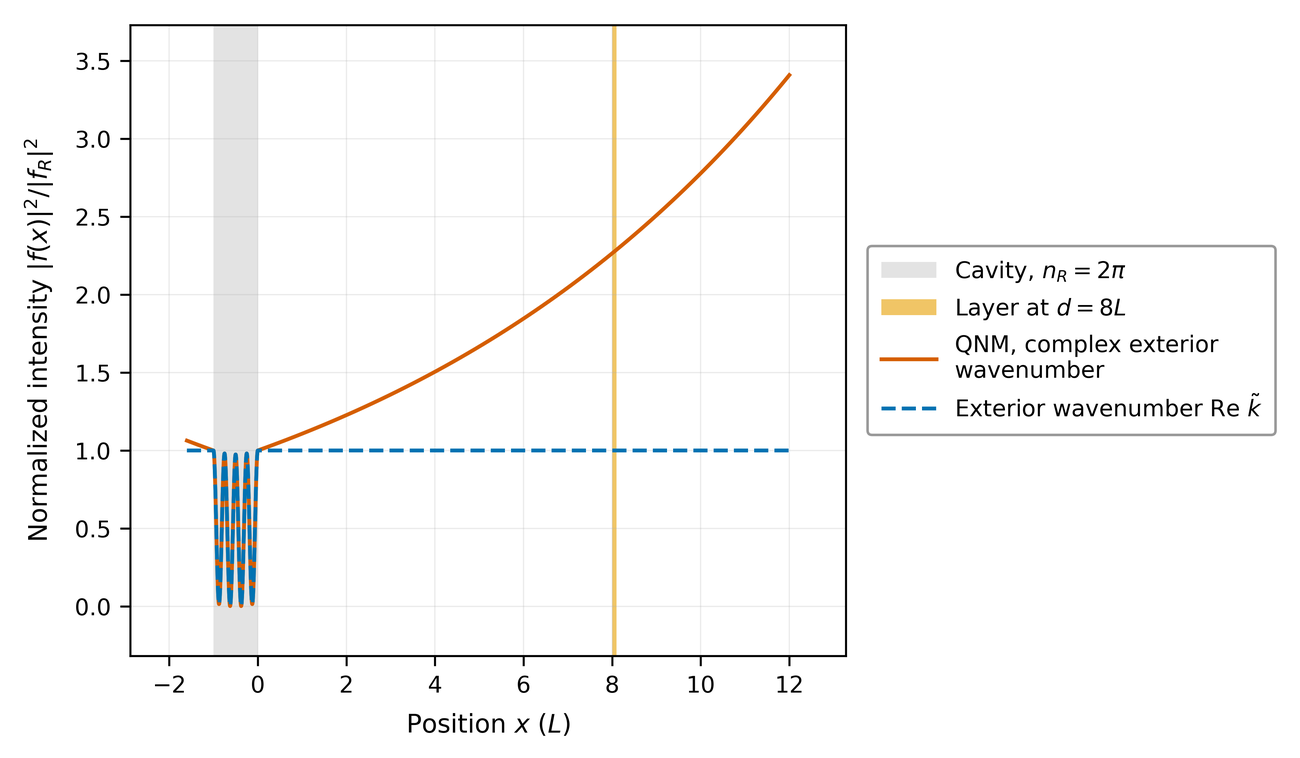

In [3]:
x = np.linspace(-1.6, 12.0, 4000)
d_demo = 8.0
fig, ax = P.new_figure(legend=True)
ax.axvspan(-L, 0.0, color=C["grey"], alpha=0.2, lw=0, label=r"Cavity, $n_R = 2\pi$")
ax.axvspan(d_demo, d_demo + LP, color=C["orange"], alpha=0.6, lw=0, label=r"Layer at $d = 8L$")
ax.plot(x, np.abs(FIELD(x))**2 / abs(F_RIGHT)**2, color=C["vermillion"],
        label="QNM, complex exterior\nwavenumber")
ax.plot(x, np.abs(FIELD(x, k_ext=K0.real))**2 / abs(F_RIGHT)**2, "--", color=C["blue"],
        label=r"Exterior wavenumber Re $\tilde{k}$")
P.label(ax, r"Position $x$ ($L$)", r"Normalized intensity $|f(x)|^2 / |f_R|^2$")
P.legend_outside(fig, ax)
publish(fig, 1, "mode_intensity", "analytic",
        r"Intensity of the $\mu = 4$ slab mode ($n_R = 2\pi$, $Q = 19.57$), normalized to its value at "
        r"the right cavity face. Outside the cavity the QNM intensity grows as $e^{\gamma_f x}$ with "
        r"$\gamma_f = 0.102\,L^{-1}$; continued with the real wavenumber it stays constant. The shaded "
        r"bands mark the cavity and a perturbing layer at $d = 8L$.")

## 4. Validation of the numerical tools

Before any production computation, the tools are checked against results that are known independently:

1. the transfer-matrix poles of the isolated slab against Eq. (2);
2. flux conservation of the transfer matrices on the real axis;
3. the transfer-matrix poles of the double barrier against the closed-form two-slab condition of Franke *et al.* [Phys. Rev. A **108**, 043502 (2023), Eq. (30)], an independent implementation;
4. double-precision poles against 50-digit Muller iteration;
5. first-order theory for a layer *inside* the cavity, where the exterior growth plays no role and the error must be second order in $\delta$;
6. the closed-form overlap, Eq. (5), against quadrature;
7. the RSE for a homogeneous change of the basis slab, whose exact answer is Eq. (2);
8. the residue $R$ and background ratio $\alpha$ of Eq. (11) against a contour integral of the transfer-matrix reflection;
9. the Fabry–Pérot condition, Eq. (7), at exact poles;
10. the self-consistent and resummed fixed points and their small-$\delta$ limit;
11. the second Born term of the layer reflection.

In [4]:
bench = []


def record(name, value, criterion, passed):
    bench.append({"benchmark": name, "value": float(value), "criterion": criterion,
                  "pass": bool(passed)})


def reflection(k, structure):
    return transmission_reflection(k, structure, N_B)[1]


# 1. Slab poles against the closed form, Eq. (2).
dev = [abs(find_pole(lambda kk: dispersion(kk, [(N_R, L)], N_B), k * (1 + 1e-3), ROOT_TOL) - k) / abs(k)
       for k in k_modes.values()]
record("1 Slab poles: transfer matrix vs Eq. (2), relative deviation", max(dev), "< 1e-12", max(dev) < 1e-12)

# 2. Flux conservation on the real axis.
worst = 0.0
for d, delta in [(0.5, 1e-3), (3.0, 0.1), (20.0, 1.0)]:
    for k in np.linspace(0.2, 6.0, 400):
        t, r = transmission_reflection(k, layers(d, delta), N_B)
        worst = max(worst, abs(abs(t)**2 + abs(r)**2 - 1.0))
record("2 Flux conservation, max ||t|^2 + |r|^2 - 1|", worst, "< 1e-12", worst < 1e-12)


# 3. Independent closed-form pole condition of two slabs (Franke et al., Eq. (30)).
def two_slab_condition(k, d, n1, n2, lp=LP):
    p1, m1, p2, m2 = n1 + N_B, n1 - N_B, n2 + N_B, n2 - N_B
    e1, e2, ed = np.exp(2j * n1 * k * L), np.exp(2j * n2 * k * lp), np.exp(2j * N_B * k * d)
    value = (p1**2 * p2**2 - m1**2 * p2**2 * e1 + m1**2 * m2**2 * e1 * e2 - p1**2 * m2**2 * e2
             + p1 * m1 * p2 * m2 * ed * (e1 - 1.0 + e2) - p1 * m1 * p2 * m2 * ed * e1 * e2)
    return value / (p1**2 * p2**2)


worst = 0.0
for d, delta in [(0.3, 1e-2), (2.0, 0.1), (8.0, 1e-3), (15.0, 0.5)]:
    n_p = np.sqrt(N_B**2 + contrast(delta))
    k_tmm = find_pole(lambda kk: dispersion(kk, layers(d, delta), N_B), K0, ROOT_TOL)
    k_eq = find_pole(lambda kk: two_slab_condition(kk, d, N_R, n_p), k_tmm, 1e-13)
    worst = max(worst, abs(k_eq - k_tmm) / abs(k_tmm))
record("3 Double barrier: transfer matrix vs closed-form condition", worst, "< 1e-10", worst < 1e-10)

# 4. 50-digit Muller iteration.
mp.mp.dps = 50


def dispersion_mp(k, structure):
    m11, m12, m21, m22 = mp.mpc(1), mp.mpc(0), mp.mpc(0), mp.mpc(1)
    n_prev = mp.mpf(1)
    for n, thickness in list(structure) + [(mp.mpf(1), None)]:
        r, inv_t = (n_prev - n) / (n_prev + n), (n_prev + n) / (2 * n_prev)
        m11, m12, m21, m22 = ((m11 + m12 * r) * inv_t, (m11 * r + m12) * inv_t,
                              (m21 + m22 * r) * inv_t, (m21 * r + m22) * inv_t)
        if thickness is not None:
            phase = mp.exp(1j * n * k * thickness)
            m11, m12, m21, m22 = m11 / phase, m12 * phase, m21 / phase, m22 * phase
        n_prev = n
    return m11


worst = 0.0
for d, delta in [(0.5, 1e-3), (8.0, 1e-2), (25.0, 1e-3)]:
    k_dbl = find_pole(lambda kk: dispersion(kk, layers(d, delta), N_B), K0, ROOT_TOL)
    n_r_mp = 2 * mp.pi
    structure = [(n_r_mp, mp.mpf(1)), (mp.mpf(1), mp.mpf(d)),
                 (mp.sqrt(1 + mp.mpf(delta) * (n_r_mp**2 - 1)), mp.mpf("0.1"))]
    guess = mp.mpc(k_dbl.real, k_dbl.imag)
    k_mp = mp.findroot(lambda kk: dispersion_mp(kk, structure),
                       (guess, guess * (1 + mp.mpf("1e-4")), guess * (1 - mp.mpf("1e-4"))),
                       solver="muller", tol=mp.mpf("1e-45"))
    worst = max(worst, float(abs(k_mp - guess) / abs(guess)))
mp.mp.dps = 15
record("4 Double-precision poles vs 50-digit Muller iteration", worst, "< 1e-12", worst < 1e-12)

# 5. Layer inside the cavity, [-0.55L, -0.45L]: first-order error must be second order.
x_in = np.linspace(-0.55, -0.45, 20001)
overlap_in = np.trapezoid(FIELD(x_in)**2, x_in)
deltas_in = DELTAS[DELTAS <= 0.1]
fun_in = lambda k, s: dispersion(k, [(N_R, 0.45), (np.sqrt(N_R**2 + contrast(s)), 0.10), (N_R, 0.45)], N_B)
roots_in, _ = track_pole_adaptive(fun_in, np.concatenate([[0.0], deltas_in]), K0, GAMMA0 / 4, ROOT_TOL)
interior = pd.DataFrame({"delta": deltas_in, "shift_exact": roots_in[1:] - K0,
                         "shift_first_order": -(K0 / 2) * contrast(deltas_in) * overlap_in})
interior["rel_error"] = np.abs(interior.shift_first_order - interior.shift_exact) / np.abs(interior.shift_exact)
sub = interior[interior.delta <= 1e-2]
slope_in, _, sigma_in, _ = hac_linfit(np.log(sub.delta), np.log(sub.rel_error))
record("5a Interior layer: exponent of first-order error in delta", slope_in, "1 +/- 0.05", abs(slope_in - 1) < 0.05)
err_in = interior[interior.delta <= 1e-3].rel_error.max()
record("5b Interior layer: largest first-order error, delta <= 1e-3", err_in, "< 1e-3", err_in < 1e-3)

# 6. Closed-form exterior overlap against quadrature.
worst = 0.0
for d in (0.3, 5.0, 25.0):
    xq = np.linspace(d, d + LP, 4001)
    for k_ext in (None, K0.real):
        quad = -(K0 / 2) * contrast(1e-3) * np.trapezoid(FIELD(xq, k_ext=k_ext)**2, xq)
        closed = exterior_overlap(K0 if k_ext is None else k_ext, MU, d, contrast(1e-3), N_R, L, LP, N_B)
        worst = max(worst, abs(quad - closed) / abs(closed))
record("6 Exterior overlap: Eq. (5) vs quadrature", worst, "< 1e-7", worst < 1e-7)

# 7. RSE for a homogeneous change of the basis slab.
errors_h = []
for n_basis in (25, 51, 101, 201, 401):
    target = basis_wavenumbers(MU, N_R**2 + 1.0, 0.5)
    values = rse_wavenumbers((n_basis - 1) // 2, N_R**2, 0.5, [(-0.5, 0.5, 1.0)])
    errors_h.append(abs(nearest(values, target) - target) / abs(target))
record("7a RSE, homogeneous change: relative error at N = 401", errors_h[-1], "< 1e-6", errors_h[-1] < 1e-6)
record("7b RSE, homogeneous change: monotone convergence (1 = yes)",
       float(np.all(np.diff(errors_h) < 0)), "1", np.all(np.diff(errors_h) < 0))

# 8. Residue and background ratio from a contour integral of the slab reflection.
theta = np.linspace(0.0, 2 * np.pi, 4097)[:-1]
ring = K0 + 0.1 * np.exp(1j * theta)
jac = 0.1j * np.exp(1j * theta)
rho = np.array([reflection(k, [(N_R, L)]) for k in ring])
residue_num = np.mean(rho * jac) / 1j
rho_bg_num = np.mean((rho - residue_num / (ring - K0)) / (ring - K0) * jac) / 1j
alpha_num = rho_bg_num / residue_num
record("8a Residue: contour integral vs i n_B f_R^2", abs(residue_num - RESIDUE) / abs(RESIDUE), "< 1e-10",
       abs(residue_num - RESIDUE) / abs(RESIDUE) < 1e-10)
record("8b Background ratio: contour integral vs Eq. (11)", abs(alpha_num - ALPHA) / abs(ALPHA), "< 1e-10",
       abs(alpha_num - ALPHA) / abs(ALPHA) < 1e-10)

# 9. Fabry-Perot condition, Eq. (7), at exact poles.
worst = 0.0
for d, delta in [(0.5, 1e-3), (5.0, 0.1), (20.0, 1e-2)]:
    k_ex = find_pole(lambda kk: dispersion(kk, layers(d, delta), N_B), K0, ROOT_TOL)
    n_p = np.sqrt(N_B**2 + contrast(delta))
    residual = 1.0 - reflection(k_ex, [(N_R, L)]) * reflection(k_ex, [(n_p, LP)]) * np.exp(2j * N_B * k_ex * d)
    worst = max(worst, abs(residual))
record("9 Fabry-Perot condition at exact poles, |1 - rho_c rho_p exp(2i n_B k d)|", worst, "< 1e-8", worst < 1e-8)

# 10. Fixed points and the small-strength limit.
for alpha, name in ((0.0, "self-consistent"), (ALPHA, "resummed")):
    dk, _ = solve_shift(MU, 12.0, contrast(1e-3), N_R, alpha, None, L, LP, N_B)
    g, _ = pole_function(K0 + dk, MU, 12.0, contrast(1e-3), N_R, L, LP, N_B)
    residual = abs(dk - g / (1 - alpha * g)) / abs(dk)
    record(f"10a {name.capitalize()} fixed-point residual", residual, "< 1e-13", residual < 1e-13)
    dk_small, _ = solve_shift(MU, 12.0, contrast(1e-9), N_R, alpha, None, L, LP, N_B)
    ratio = abs(dk_small / naive_shift(MU, 12.0, contrast(1e-9), N_R, L, LP, N_B) - 1.0)
    record(f"10b {name.capitalize()} vs naive at delta = 1e-9, |ratio - 1|", ratio, "< 1e-6", ratio < 1e-6)

# 11. Second Born term of the layer reflection: the remainder must be third order.
remainders = []
for delta in (1e-3, 1e-2):
    k, dv = 2.0 - 0.05j, contrast(delta)
    e_p = np.exp(2j * N_B * k * LP)
    born_1 = dv * (e_p - 1.0) / (4 * N_B**2)
    born_2 = born_1 * dv * (1j * k * LP * e_p / (N_B * (e_p - 1.0)) - 0.5 / N_B**2)
    exact_r = reflection(k, [(np.sqrt(N_B**2 + dv), LP)])
    remainders.append(abs(exact_r - born_1 - born_2) / abs(born_1))
order = np.log10(remainders[1] / remainders[0])
record("11 Layer reflection: order of the remainder after two Born terms (relative)", order, "2 +/- 0.05",
       abs(order - 2) < 0.05)

benchmarks = pd.DataFrame(bench)
benchmarks.to_csv(RESULTS / "benchmarks.csv", index=False)
interior.assign(shift_exact_re=interior.shift_exact.apply(np.real), shift_exact_im=interior.shift_exact.apply(np.imag),
                shift_first_order_re=interior.shift_first_order.apply(np.real),
                shift_first_order_im=interior.shift_first_order.apply(np.imag)).drop(
    columns=["shift_exact", "shift_first_order"]).to_csv(RESULTS / "interior_control.csv", index=False)
display(benchmarks)
assert benchmarks["pass"].all(), "a validation benchmark failed"
summary["benchmarks"] = {row.benchmark: {"value": row.value, "criterion": row.criterion, "pass": row["pass"]}
                         for _, row in benchmarks.iterrows()}
summary["interior_control"] = {"exponent": slope_in, "exponent_sigma": sigma_in, "max_error_delta_le_1e-3": err_in}

,benchmark,value,criterion,pass
0,"1 Slab poles: transfer matrix vs Eq. (2), rela...",1.38733e-17,< 1e-12,True
1,"2 Flux conservation, max ||t|^2 + |r|^2 - 1|",3.33067e-15,< 1e-12,True
2,3 Double barrier: transfer matrix vs closed-fo...,2.08130e-17,< 1e-10,True
3,4 Double-precision poles vs 50-digit Muller it...,6.86739e-17,< 1e-12,True
4,5a Interior layer: exponent of first-order err...,1.00038e+00,1 +/- 0.05,True
5,"5b Interior layer: largest first-order error, ...",2.94407e-04,< 1e-3,True
6,6 Exterior overlap: Eq. (5) vs quadrature,8.33881e-10,< 1e-7,True
7,"7a RSE, homogeneous change: relative error at ...",4.46864e-12,< 1e-6,True
8,"7b RSE, homogeneous change: monotone convergen...",1.00000e+00,1,True
9,8a Residue: contour integral vs i n_B f_R^2,1.54597e-16,< 1e-10,True


## 5. Exact poles of the perturbed structure

For each mode $\mu \in \{2, 4, 8\}$ and each of the 44 gaps, the pole is continued in $\delta$ from the unperturbed mode through the 13 strengths. This is the pole that a perturbation series in $\delta$ approximates, and it is the reference for every error reported below.

Two other conventions appear in the literature and in our earlier analysis. Continuation in $d$ at fixed $\delta$ follows the pole as the layer is moved away; near an avoided crossing it can pass to a pole of the gap resonator formed by the cavity and the layer. Fixed-step tracking on the gap grid, started from the unperturbed pole, can jump between poles when they approach each other. The table lists the tracks on which these conventions differ from continuation in $\delta$.

In [5]:
def exact_poles(mu, gaps, strengths, n_r=N_R, lp=LP, sign=1.0):
    # Poles continued in the strength from the unperturbed mode, separately at every gap.
    k0 = slab_wavenumber(mu, n_r, L, N_B)
    poles = np.empty((len(gaps), len(strengths)), dtype=complex)
    ok = True
    for i, d in enumerate(gaps):
        fun = lambda k, s: dispersion(k, layers(d, s, n_r, lp, sign), N_B)
        roots, flags = track_pole_adaptive(fun, np.concatenate([[0.0], strengths]), k0, abs(k0.imag) / 4, ROOT_TOL)
        poles[i], ok = roots[1:], ok and bool(flags.all())
    return poles, ok


def exact_at(mu, delta, gaps, n_r=N_R, lp=LP, sign=1.0):
    poles, ok = exact_poles(mu, gaps, np.linspace(0.0, delta, 9)[1:], n_r, lp, sign)
    return poles[:, -1], ok


t0 = time.time()
records, tracking = [], []
for mu in MODES:
    k0 = k_modes[mu]
    poles, ok = exact_poles(mu, GAPS, DELTAS)
    for j, delta in enumerate(DELTAS):
        fun_d = lambda k, d: dispersion(k, layers(d, delta), N_B)
        along_d, _ = track_pole_adaptive(fun_d, GAPS, poles[0, j], abs(k0.imag) / 4, ROOT_TOL)
        fixed = track_pole(fun_d, GAPS, k0, ROOT_TOL)
        diff_d = np.abs(along_d - poles[:, j]) > 1e-8 * np.abs(poles[:, j])
        diff_f = np.abs(fixed - poles[:, j]) > 1e-8 * np.abs(poles[:, j])
        tracking.append({"mode": mu, "delta": delta, "continuation_ok": ok,
                         "gap_continuation_points_differing": int(diff_d.sum()),
                         "fixed_step_points_differing": int(diff_f.sum()),
                         "first_gap_differing": float(GAPS[np.argmax(diff_d)]) if diff_d.any() else np.nan})
        records += [{"mu": mu, "delta": delta, "d": d, "k_exact": k} for d, k in zip(GAPS, poles[:, j])]
grid = pd.DataFrame(records)
tracking = pd.DataFrame(tracking)
tracking.to_csv(RESULTS / "tracking.csv", index=False)
print(f"{len(grid)} exact poles in {time.time() - t0:.1f} s; all continuations complete: "
      f"{tracking.continuation_ok.all()}")
display(tracking[(tracking.gap_continuation_points_differing > 0) | (tracking.fixed_step_points_differing > 0)])
differ_d = tracking.gap_continuation_points_differing > 0
differ_f = tracking.fixed_step_points_differing > 0
summary["tracking"] = {
    "tracks": len(tracking), "poles": len(grid), "continuation_ok": bool(tracking.continuation_ok.all()),
    "gap_continuation_tracks_differing": int(differ_d.sum()),
    "gap_continuation_points_differing": int(tracking.gap_continuation_points_differing.sum()),
    "gap_continuation_min_delta_differing": float(tracking[differ_d].delta.min()) if differ_d.any() else None,
    "fixed_step_tracks_differing": int(differ_f.sum()),
    "fixed_step_points_differing": int(tracking.fixed_step_points_differing.sum()),
    "fixed_step_min_delta_differing": float(tracking[differ_f].delta.min()) if differ_f.any() else None}
print(json.dumps(summary["tracking"], indent=1))

1716 exact poles in 0.8 s; all continuations complete: True


,mode,delta,continuation_ok,gap_continuation_points_differing,fixed_step_points_differing,first_gap_differing
7,2,0.02154,True,6,0,18.16881
8,2,0.04642,True,11,4,11.00353
9,2,0.10000,True,15,5,7.36709
10,2,0.21544,True,21,21,4.03592
11,2,0.46416,True,39,39,0.65938
12,2,1.00000,True,39,39,0.65938
17,4,0.00215,True,1,1,30.00000
18,4,0.00464,True,1,1,30.00000
19,4,0.01000,True,3,1,24.54728
20,4,0.02154,True,12,1,9.95343


{
 "tracks": 39,
 "poles": 1716,
 "continuation_ok": true,
 "gap_continuation_tracks_differing": 23,
 "gap_continuation_points_differing": 545,
 "gap_continuation_min_delta_differing": 0.002154434690031882,
 "fixed_step_tracks_differing": 20,
 "fixed_step_points_differing": 339,
 "fixed_step_min_delta_differing": 0.002154434690031882
}


### Mode identity check

As an independent criterion we search, at every gap $d \ge 4L$ and every strength for $\mu = 4$, for all poles within $0.45\,L^{-1}$ of the reference pole (27 Newton seeds) and select the pole with the smallest $|\mathrm{Im}\,k|$, the narrowest resonance near the cavity frequency. We record whether this minimal-loss pole is the reference pole and how far the nearest competing pole lies, in units of the shift $|\Delta k|$. Cells where the two criteria disagree are marked on the validity maps of Sec. 13 and discussed in Sec. 15.

In [6]:
def pole_scan(structure, center):
    found = [center]
    for dre in np.linspace(-0.45, 0.45, 9):
        for dim in (0.0, -0.08, -0.2):
            try:
                k = find_pole(lambda kk: dispersion(kk, structure, N_B), center + dre + 1j * dim, 1e-11)
            except RuntimeError:
                continue
            if all(abs(k - q) > 1e-6 for q in found):
                found.append(k)
    return np.array(found)


t0 = time.time()
rows = []
for row in grid[(grid.mu == MU) & (grid.d >= 4.0)].itertuples():
    k_track = row.k_exact
    poles = pole_scan(layers(row.d, row.delta), k_track)
    near = poles[np.abs(poles.real - k_track.real) < 0.45]
    pick = near[np.argmin(np.abs(near.imag))]
    others = near[np.abs(near - k_track) > 1e-8]
    rows.append({"delta": row.delta, "d": row.d, "agree": bool(abs(pick - k_track) < 1e-8),
                 "margin": float(np.min(np.abs(others - k_track)) / abs(k_track - K0)) if len(others) else np.inf,
                 "poles_found": len(near)})
identity = pd.DataFrame(rows)
identity.to_csv(RESULTS / "identity.csv", index=False)
print(f"{len(identity)} cells checked in {time.time() - t0:.1f} s; disagreements: {int((~identity.agree).sum())}")

273 cells checked in 0.6 s; disagreements: 64


## 6. Perturbative schemes on the full parameter grid

On every grid point we evaluate the naive and regularized first-order shifts and solve the fixed-point equations of the self-consistent and resummed schemes (Sec. 2.5). The resummed scheme is evaluated with the exact background ratio of Eq. (11), with the coupled-mode estimate $\alpha \approx i/\gamma_0$, and with the second Born term of the layer reflection. The relative error of a scheme is $|\Delta k_{\rm scheme} - \Delta k_{\rm exact}|/|\Delta k_{\rm exact}|$.

In [7]:
def scheme_track(mu, delta, gaps, alpha, n_r=N_R, lp=LP, sign=1.0, born_order=1):
    # Fixed points along the gap grid: Newton from the naive shift, then from the previous gap.
    k0 = slab_wavenumber(mu, n_r, L, N_B)
    dv = sign * contrast(delta, n_r)
    values, ok = np.full(len(gaps), np.nan + 0j), np.zeros(len(gaps), dtype=bool)
    for i, d in enumerate(gaps):
        dk, conv = solve_shift(mu, d, dv, n_r, alpha, None, L, lp, N_B, born_order)
        if not conv and i > 0 and ok[i - 1]:
            guess = values[i - 1] * np.exp(2j * N_B * k0 * (d - gaps[i - 1]))
            dk, conv = solve_shift(mu, d, dv, n_r, alpha, guess, L, lp, N_B, born_order)
        values[i], ok[i] = dk, conv
    return values, ok


SCHEME_SET = (("sc", 0.0, 1), ("res", ALPHA, 1), ("res_cm", ALPHA_CM, 1), ("res2", ALPHA, 2))
t0 = time.time()
parts = []
for (mu, delta), g in grid.groupby(["mu", "delta"]):
    g = g.sort_values("d").copy()
    dv = contrast(delta)
    g["shift_exact"] = g.k_exact - k_modes[mu]
    g["naive"] = [naive_shift(mu, d, dv, N_R, L, LP, N_B) for d in g.d]
    g["reg"] = [regularized_shift(mu, d, dv, N_R, L, LP, N_B) for d in g.d]
    for name, alpha, order in SCHEME_SET:
        g[name], g[name + "_ok"] = scheme_track(mu, delta, g.d.values, alpha, born_order=order)
    parts.append(g)
maps = pd.concat(parts, ignore_index=True)
for name in ("naive", "reg", "sc", "res", "res_cm", "res2"):
    maps["err_" + name] = np.abs(maps[name] - maps.shift_exact) / np.abs(maps.shift_exact)
maps = maps.merge(identity.assign(mu=MU)[["mu", "delta", "d", "agree", "margin"]],
                  on=["mu", "delta", "d"], how="left")
print(f"schemes evaluated in {time.time() - t0:.1f} s")


def complex_to_columns(df, names):
    out = df.copy()
    for name in names:
        values = out[name].to_numpy(dtype=complex)
        out[name + "_re"], out[name + "_im"] = values.real, values.imag
    return out.drop(columns=list(names))


complex_to_columns(maps, ["k_exact", "shift_exact", "naive", "reg", "sc", "res", "res_cm", "res2"]).to_csv(
    RESULTS / "shifts_and_errors.csv", index=False)

m4 = maps[maps.mu == MU]
convergence = {name: float(m4[name + "_ok"].mean()) for name, _, _ in SCHEME_SET}
print("fraction of the mu = 4 grid on which the fixed point was found:", convergence)
summary["convergence_fraction"] = convergence


# The self-consistent scheme with the prefactor held at k0, dk = F(k0 + dk), for comparison.
def selfconsistent_fixed_prefactor(mu, d, dv):
    k0 = k_modes[mu]
    dk = naive_shift(mu, d, dv, N_R, L, LP, N_B)
    for _ in range(100):
        h = 1e-7
        value = exterior_overlap(k0 + dk, mu, d, dv, N_R, L, LP, N_B)
        slope = (exterior_overlap(k0 + dk + h, mu, d, dv, N_R, L, LP, N_B)
                 - exterior_overlap(k0 + dk - h, mu, d, dv, N_R, L, LP, N_B)) / (2 * h)
        step = (dk - value) / (1.0 - slope)
        dk -= step
        if not np.isfinite(dk) or abs(dk) > abs(k0) / 2:
            return complex(np.nan, np.nan)
        if abs(step) < 1e-12 * abs(dk):
            return dk
    return complex(np.nan, np.nan)


ok = m4[m4.sc_ok]
variant = np.array([selfconsistent_fixed_prefactor(MU, r.d, contrast(r.delta)) for r in ok.itertuples()])
err_variant = np.abs(variant - ok.shift_exact.values) / np.abs(ok.shift_exact.values)
finite = np.isfinite(err_variant)
diff = np.abs(err_variant[finite] - ok.err_sc.values[finite]) / ok.err_sc.values[finite]
summary["sc_prefactor_variant"] = {"median_rel_change_of_error": float(np.median(diff)),
                                   "p90_rel_change_of_error": float(np.quantile(diff, 0.9))}
print(f"holding the prefactor at k0 changes the self-consistent error by a median {np.median(diff):.2%}")

schemes evaluated in 0.4 s
fraction of the mu = 4 grid on which the fixed point was found: {'sc': 0.9895104895104895, 'res': 1.0, 'res_cm': 1.0, 'res2': 1.0}
holding the prefactor at k0 changes the self-consistent error by a median 0.87%


## 7. Overview of the estimators

The production grid samples the gap at 44 points, too coarsely to resolve the oscillation of the shift with the round-trip phase, whose period in $d$ is $\pi/(n_B\,\mathrm{Re}\,\tilde k) = 1.57\,L$. For display we therefore add line scans with 600 gaps between $0.05\,L$ and $30\,L$ at $\delta = 10^{-4}$ and $10^{-3}$ for $\mu = 4$; all fits and maps use the production grid.

Figures 2 and 3 compare the real and imaginary parts of the shift at $\delta = 10^{-3}$ with the four perturbative schemes. The Lorentzian estimator is not shown there: its systematic offset is a few per cent of the linewidth, larger than the shift itself at this strength. It is evaluated at $\delta = 0.01$ and $0.1$, where the shifts are comparable to the linewidth (Fig. 4).

**Fig. 2.** Real part of the shift of the $\mu = 4$ mode versus gap at $\delta = 10^{-3}$: exact pole and the naive, regularized, self-consistent and resummed schemes.

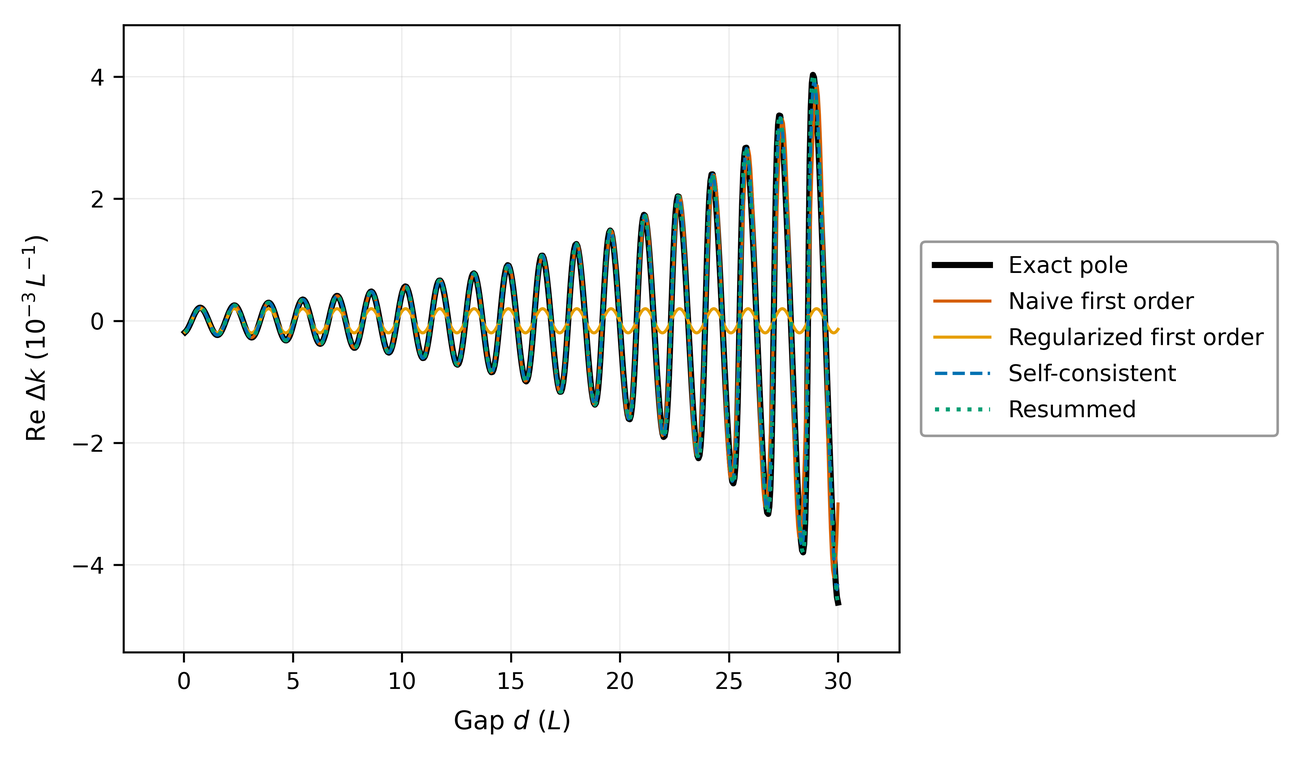

**Fig. 3.** Imaginary part of the shift for the configuration of Fig. 2. Negative values correspond to a larger radiative loss.

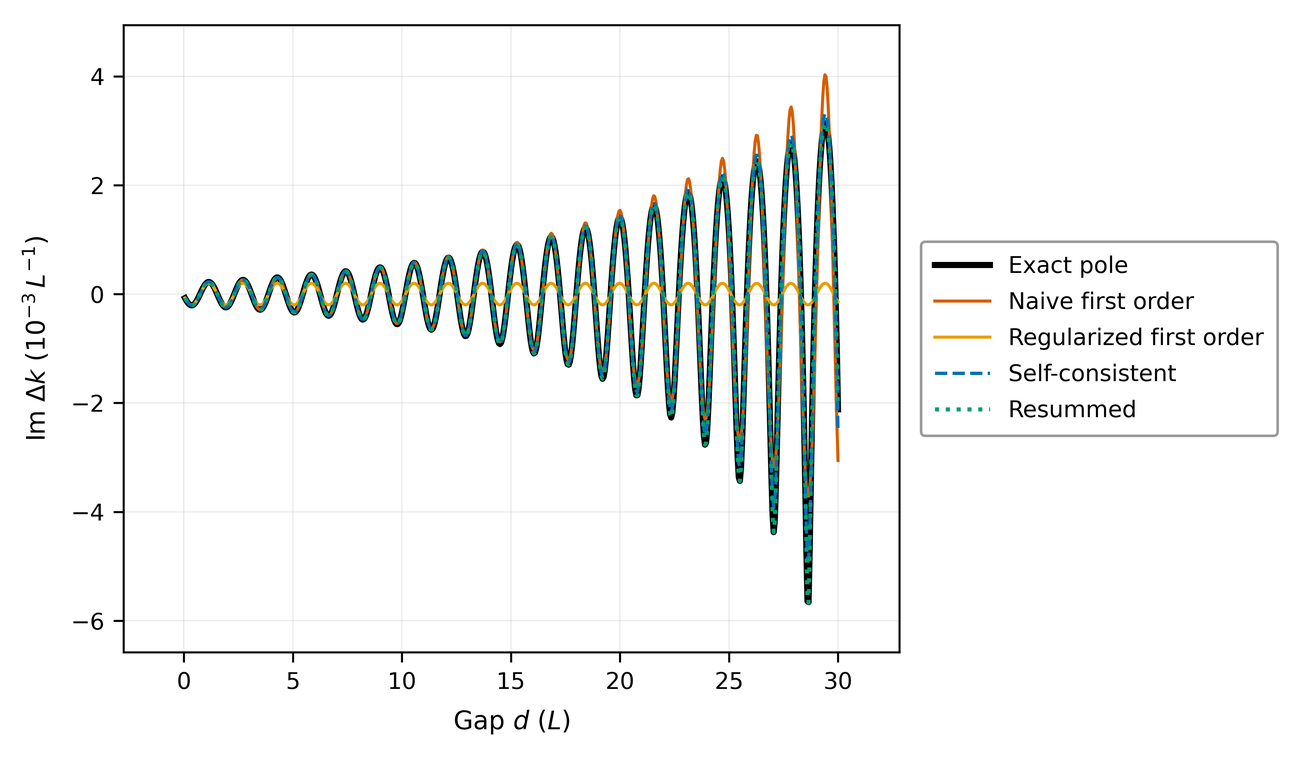

In [8]:
LINE_GAPS = np.linspace(0.05, 30.0, 600)
line = {}
for delta in (1e-4, 1e-3):
    poles, _ = exact_poles(MU, LINE_GAPS, np.linspace(0.0, delta, 9)[1:])
    dv = contrast(delta)
    scan = {"exact": poles[:, -1] - K0,
            "naive": np.array([naive_shift(MU, d, dv, N_R, L, LP, N_B) for d in LINE_GAPS]),
            "reg": np.array([regularized_shift(MU, d, dv, N_R, L, LP, N_B) for d in LINE_GAPS])}
    for name, alpha, order in (("sc", 0.0, 1), ("res", ALPHA, 1), ("res2", ALPHA, 2)):
        scan[name], ok_line = scheme_track(MU, delta, LINE_GAPS, alpha, born_order=order)
        assert ok_line.all()
    line[delta] = scan
pd.DataFrame({"d": LINE_GAPS, **{f"{name}_{part}_delta{delta:g}": fn(values)
                                  for delta, scan in line.items() for name, values in scan.items()
                                  for part, fn in (("re", np.real), ("im", np.imag))}}).to_csv(
    RESULTS / "line_scans.csv", index=False)

LINE_STYLE = {"exact": dict(color=C["black"], lw=2.4), "naive": dict(color=C["vermillion"], lw=1.2),
              "reg": dict(color=C["orange"], lw=1.2), "sc": dict(color=C["blue"], lw=1.3, ls="--"),
              "res": dict(color=C["green"], lw=1.6, ls=":"), "res2": dict(color=C["purple"], lw=1.2, ls="-.")}


def shift_figure(part, number, name, ylabel, caption, delta=1e-3):
    fig, ax = P.new_figure(legend=True)
    for key in ("exact", "naive", "reg", "sc", "res"):
        ax.plot(LINE_GAPS, part(line[delta][key]) * 1e3, label=STYLE[key][0], **LINE_STYLE[key])
    P.label(ax, r"Gap $d$ ($L$)", ylabel)
    P.legend_outside(fig, ax)
    publish(fig, number, name, "results/line_scans.csv", caption)


shift_figure(np.real, 2, "shift_real", r"Re $\Delta k$ ($10^{-3}\,L^{-1}$)",
             r"Real part of the shift of the $\mu = 4$ mode versus gap at $\delta = 10^{-3}$: exact pole "
             r"and the naive, regularized, self-consistent and resummed schemes.")
shift_figure(np.imag, 3, "shift_imag", r"Im $\Delta k$ ($10^{-3}\,L^{-1}$)",
             r"Imaginary part of the shift for the configuration of Fig. 2. Negative values correspond to a "
             r"larger radiative loss.")

88 Lorentzian fits in 0.4 s
{
 "fits": 88,
 "rejected": 28,
 "rejected_by_delta": {
  "0.1": 28
 },
 "median_dev_re": 0.020959025570169154,
 "max_dev_re": 0.45718049426772694,
 "d_at_max_dev_re": 27.137030277315603,
 "median_dev_im": 0.007333527608926192,
 "median_dev_re_by_delta": {
  "0.01": 0.01789167818273565,
  "0.1": 0.03452115835254998
 }
}


**Fig. 4.** Deviation of the Lorentzian estimate of the resonance position from the exact pole, in units of the exact linewidth $|\mathrm{Im}\,k|$, for $\delta = 0.01$ and $0.1$. Open symbols mark fits rejected by the window-stability criterion (halving the fit window moves the centre by more than $1\%$ of $\gamma_0$).

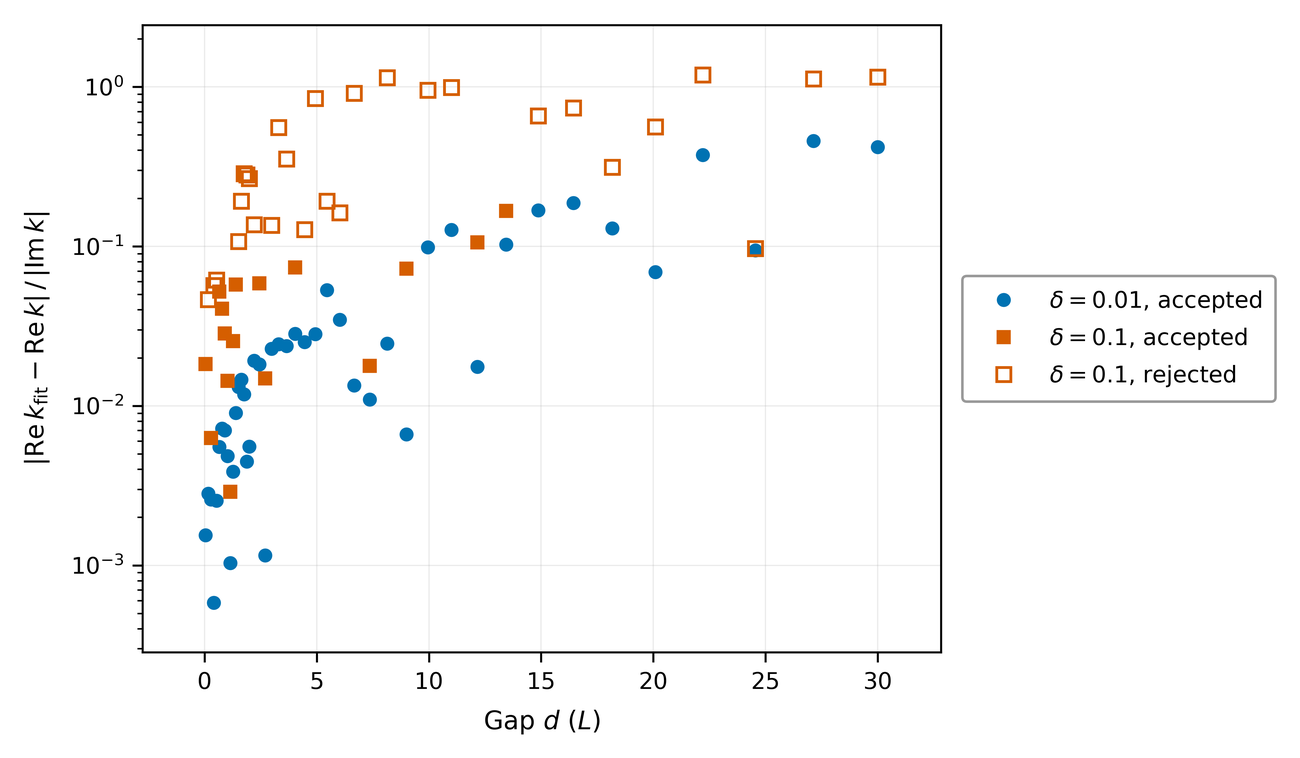

In [9]:
t0 = time.time()
rows = []
for delta in (0.01, 0.1):
    g = maps[(maps.mu == MU) & np.isclose(maps.delta, delta)].sort_values("d")
    for r in g.itertuples():
        structure = layers(r.d, delta)
        try:
            k_fit = fit_resonance(structure, r.k_exact.real, GAMMA0, N_B, half_window=3.0)
            k_half = fit_resonance(structure, r.k_exact.real, GAMMA0, N_B, half_window=1.5)
            window_shift = abs(k_half.real - k_fit.real) / GAMMA0
        except RuntimeError:
            k_fit, window_shift = complex(np.nan, np.nan), np.nan
        rows.append({"delta": delta, "d": r.d, "k_exact_re": r.k_exact.real, "k_exact_im": r.k_exact.imag,
                     "k_fit_re": k_fit.real, "k_fit_im": k_fit.imag, "window_shift": window_shift})
lorentz = pd.DataFrame(rows)
lorentz["accepted"] = lorentz.window_shift < 0.01
lorentz["dev_re"] = np.abs(lorentz.k_fit_re - lorentz.k_exact_re) / np.abs(lorentz.k_exact_im)
lorentz["dev_im"] = np.abs(lorentz.k_fit_im - lorentz.k_exact_im) / np.abs(lorentz.k_exact_im)
lorentz.to_csv(RESULTS / "lorentzian.csv", index=False)
acc = lorentz[lorentz.accepted]
summary["lorentzian"] = {
    "fits": len(lorentz), "rejected": int((~lorentz.accepted).sum()),
    "rejected_by_delta": {str(k): int(v) for k, v in lorentz[~lorentz.accepted].groupby("delta").size().items()},
    "median_dev_re": float(acc.dev_re.median()), "max_dev_re": float(acc.dev_re.max()),
    "d_at_max_dev_re": float(acc.d.iloc[int(np.argmax(acc.dev_re.values))]),
    "median_dev_im": float(acc.dev_im.median()),
    "median_dev_re_by_delta": {str(k): float(v) for k, v in acc.groupby("delta").dev_re.median().items()}}
print(f"{len(lorentz)} Lorentzian fits in {time.time() - t0:.1f} s")
print(json.dumps(summary["lorentzian"], indent=1))

fig, ax = P.new_figure(legend=True)
for delta, color, marker in ((0.01, C["blue"], "o"), (0.1, C["vermillion"], "s")):
    g = lorentz[np.isclose(lorentz.delta, delta)]
    good, bad = g[g.accepted], g[~g.accepted]
    ax.semilogy(good.d, good.dev_re, marker, color=color, ms=4.5, label=rf"$\delta = {delta:g}$, accepted")
    if len(bad):
        ax.semilogy(bad.d, bad.dev_re, marker, color=color, ms=5.5, mfc="none", mew=1.1,
                    label=rf"$\delta = {delta:g}$, rejected")
P.label(ax, r"Gap $d$ ($L$)", r"$|\mathrm{Re}\,k_{\rm fit} - \mathrm{Re}\,k| \,/\, |\mathrm{Im}\,k|$")
P.legend_outside(fig, ax)
publish(fig, 4, "lorentzian_deviation", "results/lorentzian.csv",
        r"Deviation of the Lorentzian estimate of the resonance position from the exact pole, in units of "
        r"the exact linewidth $|\mathrm{Im}\,k|$, for $\delta = 0.01$ and $0.1$. Open symbols mark fits "
        r"rejected by the window-stability criterion (halving the fit window moves the centre by more "
        r"than $1\%$ of $\gamma_0$).")

## 8. Growth of the exact shift

If the exponential growth of the exterior QNM field were an artifact of the mode basis, the exact shift would stay bounded. Figure 5 shows the opposite: at $\delta = 10^{-4}$ the exact shift grows at the field rate $\gamma_f$. The rate is the slope of $\ln|\Delta k_{\rm exact}|$ for $d \ge 8L$, with a Newey–West standard error.

,rate,sigma,sigma_ols,rate_over_gamma_f,deviation_in_sigma
2,0.10186,0.00013,0.00013,0.99677,-2.62494
4,0.10294,0.00043,0.00038,1.00736,1.73889
8,0.10369,0.00075,0.00089,1.01465,1.98789


**Fig. 5.** Magnitude of the shift of the $\mu = 4$ mode at $\delta = 10^{-4}$. The exact shift grows at $(0.1029 \pm 0.0004)\,L^{-1}$ for $d \ge 8L$, against the field rate $\gamma_f = 0.1022\,L^{-1}$ that sets the growth of the naive shift. The regularized shift stays bounded.

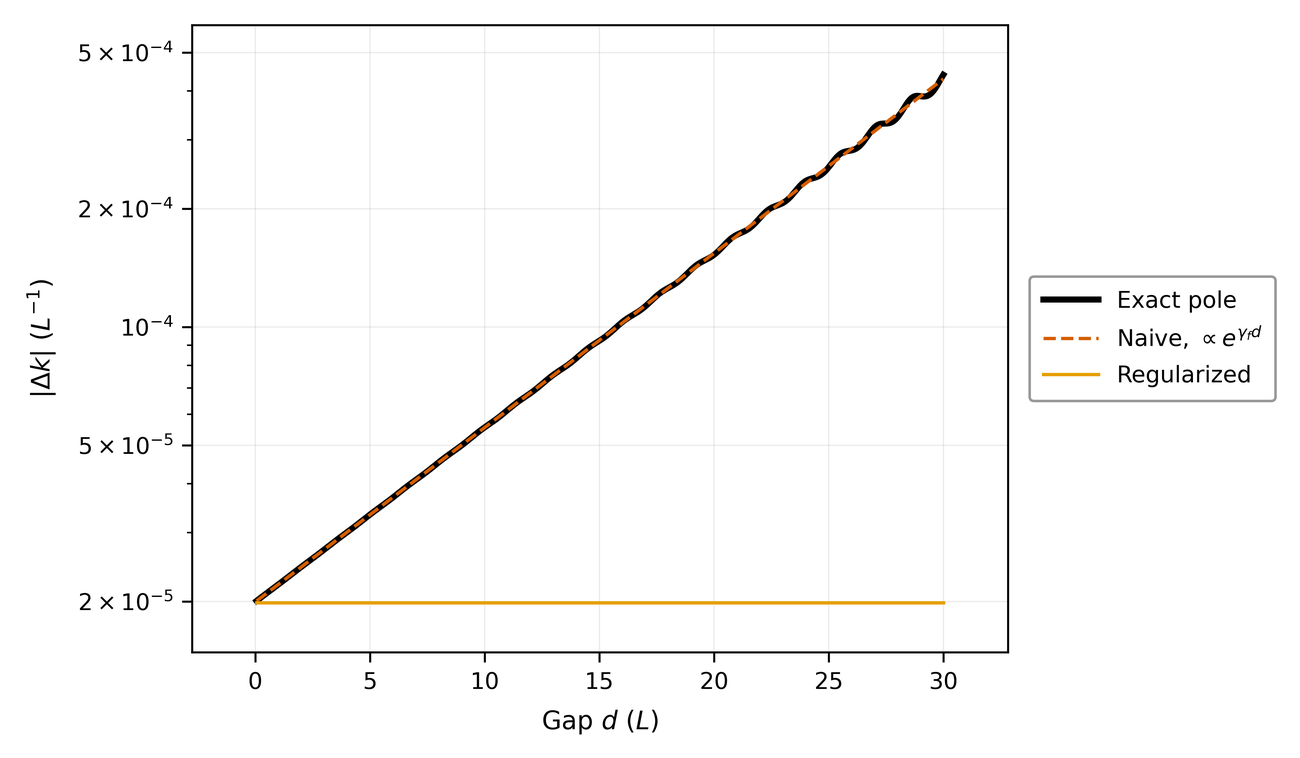

In [10]:
growth = {}
for mu in MODES:
    g = maps[(maps.mu == mu) & np.isclose(maps.delta, 1e-4) & (maps.d >= 8.0)].sort_values("d")
    slope, _, sigma, sigma_ols = hac_linfit(g.d, np.log(np.abs(g.shift_exact.to_numpy(dtype=complex))))
    growth[str(mu)] = {"rate": slope, "sigma": sigma, "sigma_ols": sigma_ols,
                       "rate_over_gamma_f": slope / GAMMA_F, "deviation_in_sigma": (slope - GAMMA_F) / sigma}
summary["exact_growth"] = growth
display(pd.DataFrame(growth).T)

fig, ax = P.new_figure(legend=True)
ax.semilogy(LINE_GAPS, np.abs(line[1e-4]["exact"]), label="Exact pole", **LINE_STYLE["exact"])
ax.semilogy(LINE_GAPS, np.abs(line[1e-4]["naive"]), color=C["vermillion"], lw=1.3, ls="--",
            label=r"Naive, $\propto e^{\gamma_f d}$")
ax.semilogy(LINE_GAPS, np.abs(line[1e-4]["reg"]), color=C["orange"], lw=1.3, label="Regularized")
P.log_ticks(ax, "y", [2e-5, 5e-5, 1e-4, 2e-4, 5e-4],
            [r"$2\times10^{-5}$", r"$5\times10^{-5}$", r"$10^{-4}$", r"$2\times10^{-4}$", r"$5\times10^{-4}$"])
P.label(ax, r"Gap $d$ ($L$)", r"$|\Delta k|$ ($L^{-1}$)")
P.legend_outside(fig, ax)
publish(fig, 5, "exact_growth", "results/line_scans.csv",
        rf"Magnitude of the shift of the $\mu = 4$ mode at $\delta = 10^{{-4}}$. The exact shift grows at "
        rf"$({growth['4']['rate']:.4f} \pm {growth['4']['sigma']:.4f})\,L^{{-1}}$ for $d \ge 8L$, against "
        rf"the field rate $\gamma_f = {GAMMA_F:.4f}\,L^{{-1}}$ that sets the growth of the naive shift. "
        r"The regularized shift stays bounded.")

## 9. Error laws of the perturbative schemes

Figure 6 shows the relative error of each scheme at $\delta = 10^{-3}$ together with the predictions of Eqs. (13), (16) and (18), which contain no fitted parameter: $|a(d)F|$ for the naive scheme, $|(\alpha + b\,e^{-2in_B\tilde kd})F|$ for the self-consistent scheme, the distance-independent $|b\,R\,\rho_p^{(1)}|$ for the resummed scheme and the floor $|1 - c\,e^{-\gamma_f d}|$ for the regularized scheme.

The analysis plan fixed before the production runs expected the naive error to grow at the field rate $\gamma_f$. The production data refute that expectation: the error grows at twice the field rate. The second-order law of Sec. 2.5 was derived afterwards to explain the doubling, and Sections 10 and 14 test it on data that did not enter its derivation.

The growth rate of the naive absolute error is fitted in two ways. The primary estimator divides the error by the exact prefactor $|a(d)|$ of Eq. (14), so that the expected slope is exactly $2\gamma_f$; the raw slope of $\ln|\Delta k_{\rm naive} - \Delta k_{\rm exact}|$ is reported as a consistency check. We also show why the full prefactor is needed: dividing by the propagation term $2n_Bd$ alone leaves the factor $|a(d)|/(2n_Bd)$, which decreases with $d$ and biases the slope low. Both are evaluated for $d \ge 8L$ at $\delta = 10^{-4}$, where $|a(d)F| < 0.04$, and at $\delta = 10^{-3}$, where third-order terms reach $|a(d)F| \approx 0.3$ at the largest gaps.

**Fig. 6.** Relative errors of the perturbative schemes for the $\mu = 4$ mode at $\delta = 10^{-3}$ (coloured lines) and the parameter-free predictions of Eqs. (13), (16) and (18) (black dashed): $|a(d)F|$ for the naive scheme, $|(\alpha + b e^{-2in_B\tilde kd})F|$ for the self-consistent scheme, $|bR\rho_p^{(1)}|$ for the resummed scheme and the floor $|1 - ce^{-\gamma_f d}|$ for the regularized scheme. With the second Born term included, the resummed error is of third order.

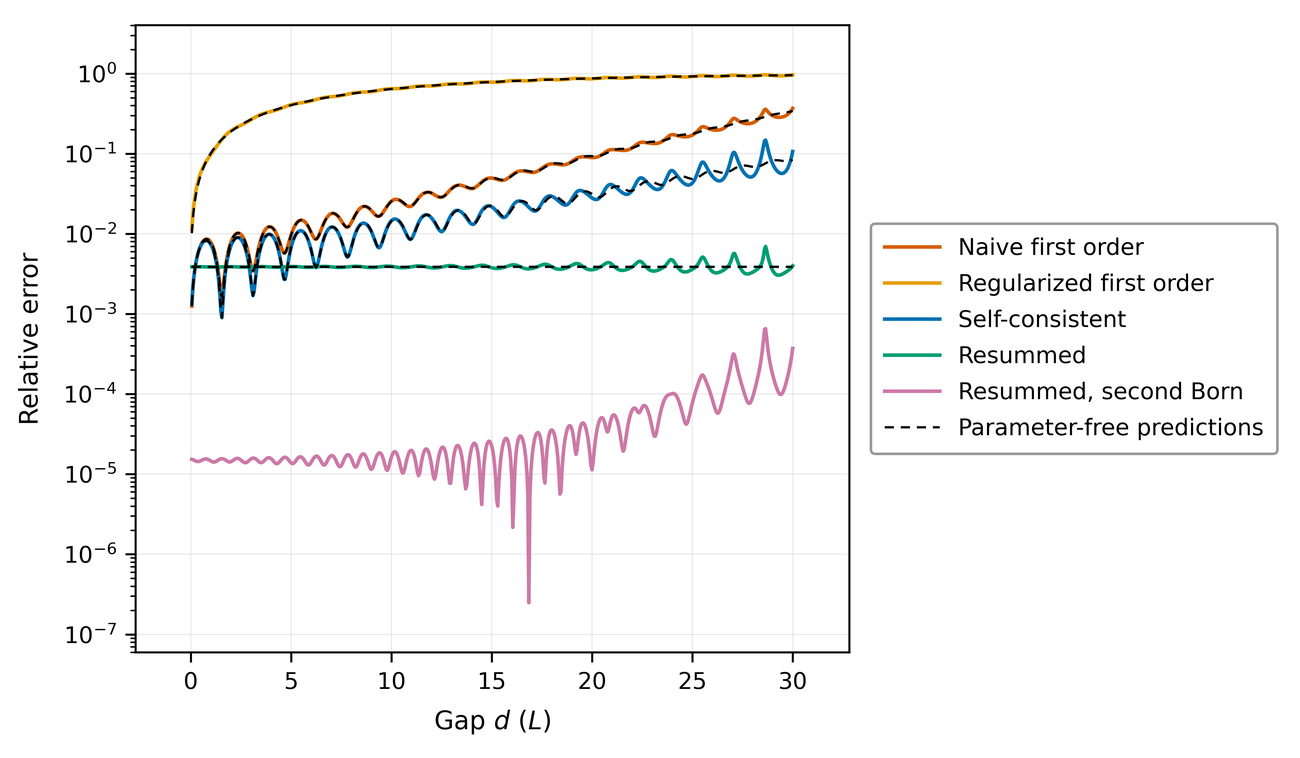

,delta,mode,corrected_rate,corrected_sigma,corrected_sigma_ols,corrected_over_2gamma_f,raw_rate,raw_sigma,raw_over_2gamma_f,ratio_median,ratio_min,ratio_max
0,0.0001,2,0.20389,0.00018,0.00019,0.99762,0.23931,0.00230,1.17093,0.99921,0.98633,1.00412
1,0.0001,4,0.20549,0.00063,0.00056,1.00542,0.24135,0.00225,1.18088,1.00043,0.97986,1.03648
2,0.0001,8,0.20658,0.00111,0.00130,1.01078,0.23884,0.00316,1.16859,1.00047,0.95591,1.11225
3,0.0010,2,0.19920,0.00193,0.00188,0.97467,0.23462,0.00359,1.14798,0.99207,0.87608,1.04304
4,0.0010,4,0.21458,0.00545,0.00555,1.04989,0.25044,0.00400,1.22535,1.00081,0.82758,1.50713
5,0.0010,8,0.22301,0.00806,0.01135,1.09117,0.25527,0.00874,1.24898,1.00338,0.66086,2.26600


{
 "d_first": 8.144324944761593,
 "d_last": 30.0,
 "ratio_first": 2.1598777443790684,
 "ratio_last": 1.3282382359435752,
 "ratio_geometric_mean": 1.7056176738120263,
 "rate": 0.1822663023377658,
 "sigma": 0.0031450227762586007,
 "rate_over_2gamma_f": 0.891801730130567
}
{
 "hac_lag": 31,
 "exact_rate_line": 0.10212184984481011,
 "exact_rate_grid": 0.10294254996729513,
 "exact_rel_change": 0.007972409103385814,
 "corrected_rate_line": 0.20428012094240286,
 "corrected_rate_grid": 0.20548659869905966,
 "corrected_rel_change": 0.005871320875887043
}
{
 "sc": {
  "median": 2.8162004920801413,
  "min": 0.9320339299303801,
  "max": 26.3872017514151,
  "cells": 176
 },
 "res": {
  "median": 20.52836210181374,
  "min": 2.9333217720381914,
  "max": 220.21149245101364,
  "cells": 182
 },
 "res_cm": {
  "median": 17.356651462103912,
  "min": 3.0597339833437243,
  "max": 470.1237606151595,
  "cells": 182
 },
 "res2": {
  "median": 363.8535130284381,
  "min": 1.205470338390299,
  "max": 41394.880840

In [11]:
def first_order(mu, d, delta, n_r=N_R, lp=LP, sign=1.0):
    return naive_shift(mu, d, sign * contrast(delta, n_r), n_r, L, lp, N_B)


def resummed_error_per_delta(mu, n_r=N_R, lp=LP):
    # |b R rho_p^(1)(k0)| / delta: relative error of the resummed scheme per unit strength.
    k0 = slab_wavenumber(mu, n_r, L, N_B)
    _, _, _, f_r = slab_mode(mu, n_r, L, N_B, x1=-L)
    b = second_order_terms(0.0, mu, n_r, 0.0, L, lp, N_B)["born"]
    e_p = np.exp(2j * N_B * k0 * lp)
    return float(abs(b * 1j * N_B * f_r**2 * contrast(1.0, n_r) * (e_p - 1.0) / (4 * N_B**2)))


KAPPA_RES = resummed_error_per_delta(MU)
scan = line[1e-3]
F1 = scan["naive"]
terms = second_order_terms(LINE_GAPS, MU, N_R, ALPHA, L, LP, N_B)
prediction = {"naive": np.abs(sum(terms.values()) * F1),
              "reg": regularization_floor(LINE_GAPS, MU, N_R, L, LP, N_B),
              "sc": np.abs((terms["background"] + terms["born"]) * F1),
              "res": np.full(len(LINE_GAPS), KAPPA_RES * 1e-3)}
fig, ax = P.new_figure(legend=True)
for key in ("naive", "reg", "sc", "res", "res2"):
    ax.semilogy(LINE_GAPS, np.abs(scan[key] - scan["exact"]) / np.abs(scan["exact"]),
                color=STYLE[key][1], lw=1.4, label=STYLE[key][0])
for i, key in enumerate(("naive", "reg", "sc", "res")):
    ax.semilogy(LINE_GAPS, prediction[key], color=C["black"], lw=0.9, ls=(0, (4, 3)),
                label="Parameter-free predictions" if i == 0 else None)
P.label(ax, r"Gap $d$ ($L$)", "Relative error")
P.legend_outside(fig, ax)
publish(fig, 6, "error_laws", "results/line_scans.csv",
        r"Relative errors of the perturbative schemes for the $\mu = 4$ mode at $\delta = 10^{-3}$ "
        r"(coloured lines) and the parameter-free predictions of Eqs. (13), (16) and (18) (black dashed): $|a(d)F|$ for "
        r"the naive scheme, $|(\alpha + b e^{-2in_B\tilde kd})F|$ for the self-consistent scheme, "
        r"$|bR\rho_p^{(1)}|$ for the resummed scheme and the floor $|1 - ce^{-\gamma_f d}|$ for the "
        r"regularized scheme. With the second Born term included, the resummed error is of third order.")

rates = []
for delta in (1e-4, 1e-3):
    for mu in MODES:
        h = maps[(maps.mu == mu) & np.isclose(maps.delta, delta) & (maps.d >= 8.0)].sort_values("d")
        err_abs = np.abs((h.naive - h.shift_exact).to_numpy(dtype=complex))
        coeff = second_order_coefficient(h.d.values, mu, N_R, ALPHA, L, LP, N_B)
        f_h = np.array([first_order(mu, d, delta) for d in h.d])
        raw = hac_linfit(h.d, np.log(err_abs))
        cor = hac_linfit(h.d, np.log(err_abs / np.abs(coeff)))
        ratio = err_abs / np.abs(coeff * f_h**2)
        rates.append({"delta": delta, "mode": mu, "corrected_rate": cor[0], "corrected_sigma": cor[2],
                      "corrected_sigma_ols": cor[3], "corrected_over_2gamma_f": cor[0] / (2 * GAMMA_F),
                      "raw_rate": raw[0], "raw_sigma": raw[2], "raw_over_2gamma_f": raw[0] / (2 * GAMMA_F),
                      "ratio_median": np.median(ratio), "ratio_min": ratio.min(), "ratio_max": ratio.max()})
rates = pd.DataFrame(rates)
rates.to_csv(RESULTS / "naive_error_rates.csv", index=False)
display(rates)

# A prefactor linear in d omits the constant part of a(d); |a(d)|/(2 n_B d) then falls with d.
h = maps[(maps.mu == MU) & np.isclose(maps.delta, 1e-4) & (maps.d >= 8.0)].sort_values("d")
err_abs = np.abs((h.naive - h.shift_exact).to_numpy(dtype=complex))
linear_ratio = np.abs(second_order_coefficient(h.d.values, MU, N_R, ALPHA, L, LP, N_B)) / (2 * N_B * h.d.values)
linear = hac_linfit(h.d, np.log(err_abs / (2 * N_B * h.d.values)))
summary["linear_prefactor"] = {"d_first": float(h.d.iloc[0]), "d_last": float(h.d.iloc[-1]),
                               "ratio_first": float(linear_ratio[0]), "ratio_last": float(linear_ratio[-1]),
                               "ratio_geometric_mean": float(np.exp(np.log(linear_ratio).mean())),
                               "rate": float(linear[0]), "sigma": float(linear[2]),
                               "rate_over_2gamma_f": float(linear[0] / (2 * GAMMA_F))}
print(json.dumps(summary["linear_prefactor"], indent=1))

# Grid convergence: the same fits on the 600-point line scan (delta = 1e-4, d >= 8 L), with the
# Newey-West lag set to the number of samples in one round-trip period of the phase oscillation.
lag = int(round(np.pi / (N_B * K0.real) / (LINE_GAPS[1] - LINE_GAPS[0])))
sel = LINE_GAPS >= 8.0
exact_line = hac_linfit(LINE_GAPS[sel], np.log(np.abs(line[1e-4]["exact"][sel])), lag)
err_line = np.abs(line[1e-4]["naive"][sel] - line[1e-4]["exact"][sel])
coeff_line = np.abs(second_order_coefficient(LINE_GAPS[sel], MU, N_R, ALPHA, L, LP, N_B))
corrected_line = hac_linfit(LINE_GAPS[sel], np.log(err_line / coeff_line), lag)
grid_exact = summary["exact_growth"][str(MU)]["rate"]
grid_corrected = rates[(rates.delta == 1e-4) & (rates["mode"] == MU)].corrected_rate.iloc[0]
summary["grid_convergence"] = {
    "hac_lag": lag, "exact_rate_line": exact_line[0], "exact_rate_grid": grid_exact,
    "exact_rel_change": abs(exact_line[0] / grid_exact - 1),
    "corrected_rate_line": corrected_line[0], "corrected_rate_grid": grid_corrected,
    "corrected_rel_change": abs(corrected_line[0] / grid_corrected - 1)}
print(json.dumps(summary["grid_convergence"], indent=1))

m4 = maps[maps.mu == MU]
far = m4[m4.d >= 8.0]


def ratio_stats(num, den, frame):
    ok = frame[np.isfinite(frame[den]) & (frame[den] > 0)]
    r = ok[num] / ok[den]
    return {"median": float(r.median()), "min": float(r.min()), "max": float(r.max()), "cells": len(r)}


at_1e3 = m4[np.isclose(m4.delta, 1e-3)]
largest = at_1e3[at_1e3.d == at_1e3.d.max()].iloc[0]
summary["error_laws"] = {
    "rates": rates.to_dict(orient="records"),
    "gain_far": {k: ratio_stats("err_naive", "err_" + k, far) for k in ("sc", "res", "res_cm", "res2")},
    "fraction_error_above_10pct": {k: float((~(m4["err_" + k] <= 0.1)).mean())
                                   for k in ("naive", "reg", "sc", "res", "res_cm", "res2")},
    "resummed_error_per_delta_predicted": KAPPA_RES,
    "resummed_error_delta_1e-3": {"min": float(at_1e3.err_res.min()), "max": float(at_1e3.err_res.max()),
                                  "median": float(at_1e3.err_res.median())},
    "res2_error_delta_1e-3": {"min": float(at_1e3.err_res2.min()), "max": float(at_1e3.err_res2.max()),
                              "median": float(at_1e3.err_res2.median())},
    "errors_delta_1e-3_d_max": {"d": float(largest.d), **{k: float(largest["err_" + k])
                                for k in ("naive", "reg", "sc", "res", "res_cm", "res2")}}}
print(json.dumps(summary["error_laws"]["gain_far"], indent=1))
print(json.dumps(summary["error_laws"]["fraction_error_above_10pct"], indent=1))
print(json.dumps(summary["error_laws"]["errors_delta_1e-3_d_max"], indent=1))

## 10. The second-order coefficient in 40-digit arithmetic

Equation (14) predicts the coefficient $a(d)$ of the second-order error with no adjustable parameter. We test it where third-order terms are negligible: at $\delta = 10^{-9}$ the exact pole is computed in 40-digit arithmetic, and $a(d) = [\Delta k_{\rm exact} - F(\tilde k)]/F(\tilde k)^2$ is compared with Eq. (13) at 48 gaps. A least-squares fit of $a(d) - 2in_Bd = a_\infty + b\,e^{-2in_B\tilde kd}$ to the 40-digit values recovers the two constants independently.

40-digit poles in 0.2 s; largest relative deviation from Eq. (14): 5.05e-07
a_inf: fit 0.49298942+20.35214611j, Eq. (14) 0.49298940+20.35214590j; b: fit -2.578960-19.172615j, Eq. (14) -2.578960-19.172615j


**Fig. 7.** Second-order coefficient $a(d)$ with the linear propagation term removed, from exact poles computed in 40-digit arithmetic at $\delta = 10^{-9}$ (symbols) and from Eq. (14) (lines). The largest relative deviation over the 48 gaps is $5.0\times10^{-7}$. The oscillation is the second Born term, which decays as $e^{-\gamma_f d}$ about the constant $a_\infty = \alpha + 2in_BL_pE/(E - 1)$.

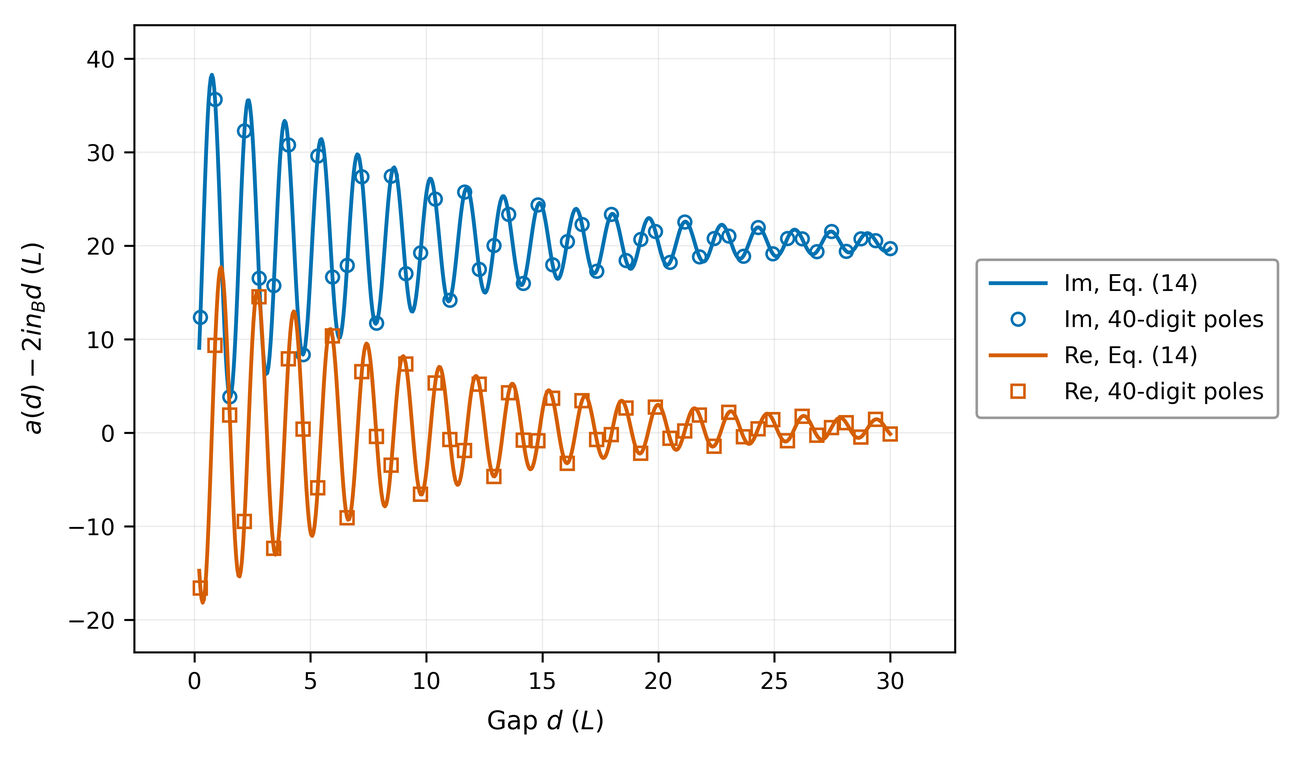

In [12]:
mp.mp.dps = 40
n_r_mp, lp_mp = 2 * mp.pi, mp.mpf("0.1")
r_mp = (n_r_mp - 1) / (n_r_mp + 1)
k0_mp = (MU * mp.pi + 1j * mp.log(r_mp)) / n_r_mp
fr2_mp = (1 - r_mp**2) / (2 * n_r_mp * r_mp)            # f_R^2 = R / (i n_B), Eq. (11)
dv_mp = mp.mpf("1e-9") * (n_r_mp**2 - 1)
e_mp = mp.exp(2j * k0_mp * lp_mp)
gaps_mp = np.linspace(0.25, 30.0, 48)
t0 = time.time()
measured = []
for d in gaps_mp:
    structure = [(n_r_mp, mp.mpf(1)), (mp.mpf(1), mp.mpf(d)), (mp.sqrt(1 + dv_mp), lp_mp)]
    f1 = 1j * dv_mp * fr2_mp * mp.exp(2j * k0_mp * mp.mpf(d)) * (e_mp - 1) / 4
    k = mp.findroot(lambda kk: dispersion_mp(kk, structure), k0_mp + f1, tol=mp.mpf(10) ** -36)
    measured.append(complex((k - k0_mp - f1) / f1**2))
mp.mp.dps = 15
measured = np.array(measured)
predicted = second_order_coefficient(gaps_mp, MU, N_R, ALPHA, L, LP, N_B)
rel_dev = np.abs(measured - predicted) / np.abs(predicted)
design = np.column_stack([np.ones_like(gaps_mp), np.exp(-2j * N_B * K0 * gaps_mp)])
(a_inf_fit, b_fit), *_ = np.linalg.lstsq(design, measured - 2j * N_B * gaps_mp, rcond=None)
t_const = second_order_terms(0.0, MU, N_R, ALPHA, L, LP, N_B)
a_inf_pred = complex(t_const["layer"] + t_const["background"])
b_pred = complex(t_const["born"])
pd.DataFrame({"d": gaps_mp, "a_measured_re": measured.real, "a_measured_im": measured.imag,
              "a_predicted_re": predicted.real, "a_predicted_im": predicted.imag}).to_csv(
    RESULTS / "second_order_coefficient_40digit.csv", index=False)
summary["mechanism_40digit"] = {
    "gaps": len(gaps_mp), "delta": 1e-9, "max_rel_dev": float(rel_dev.max()), "median_rel_dev": float(np.median(rel_dev)),
    "a_inf_fit": [a_inf_fit.real, a_inf_fit.imag], "a_inf_pred": [a_inf_pred.real, a_inf_pred.imag],
    "b_fit": [b_fit.real, b_fit.imag], "b_pred": [b_pred.real, b_pred.imag],
    "a_inf_rel_dev": abs(a_inf_fit - a_inf_pred) / abs(a_inf_pred), "b_rel_dev": abs(b_fit - b_pred) / abs(b_pred),
    "layer_term": [complex(t_const["layer"]).real, complex(t_const["layer"]).imag]}
print(f"40-digit poles in {time.time() - t0:.1f} s; largest relative deviation from Eq. (14): {rel_dev.max():.2e}")
print(f"a_inf: fit {a_inf_fit:.8f}, Eq. (14) {a_inf_pred:.8f}; b: fit {b_fit:.6f}, Eq. (14) {b_pred:.6f}")

dd = np.linspace(0.2, 30.0, 600)
curve = second_order_coefficient(dd, MU, N_R, ALPHA, L, LP, N_B) - 2j * N_B * dd
fig, ax = P.new_figure(legend=True)
ax.plot(dd, curve.imag, color=C["blue"], label=r"Im, Eq. (14)")
ax.plot(gaps_mp, (measured - 2j * N_B * gaps_mp).imag, "o", color=C["blue"], mfc="none", ms=5,
        label="Im, 40-digit poles")
ax.plot(dd, curve.real, color=C["vermillion"], label=r"Re, Eq. (14)")
ax.plot(gaps_mp, (measured - 2j * N_B * gaps_mp).real, "s", color=C["vermillion"], mfc="none", ms=5,
        label="Re, 40-digit poles")
P.label(ax, r"Gap $d$ ($L$)", r"$a(d) - 2in_Bd$ ($L$)")
P.legend_outside(fig, ax)
publish(fig, 7, "second_order_coefficient", "results/second_order_coefficient_40digit.csv",
        rf"Second-order coefficient $a(d)$ with the linear propagation term removed, from exact poles "
        rf"computed in 40-digit arithmetic at $\delta = 10^{{-9}}$ (symbols) and from Eq. (14) (lines). "
        rf"The largest relative deviation over the 48 gaps is ${tex_sci(rel_dev.max())}$. The oscillation "
        r"is the second Born term, which decays as $e^{-\gamma_f d}$ about the constant "
        r"$a_\infty = \alpha + 2in_BL_pE/(E - 1)$.")

**Fig. 8.** Magnitudes of the four terms of the second-order coefficient, Eq. (14), for the $\mu = 4$ mode. The background term $\alpha$ dominates below $d \approx |\alpha|/(2n_B) = 10\,L$ and the propagation term beyond. The second Born term nearly cancels the background term at contact and decays as $e^{-\gamma_f d}$.

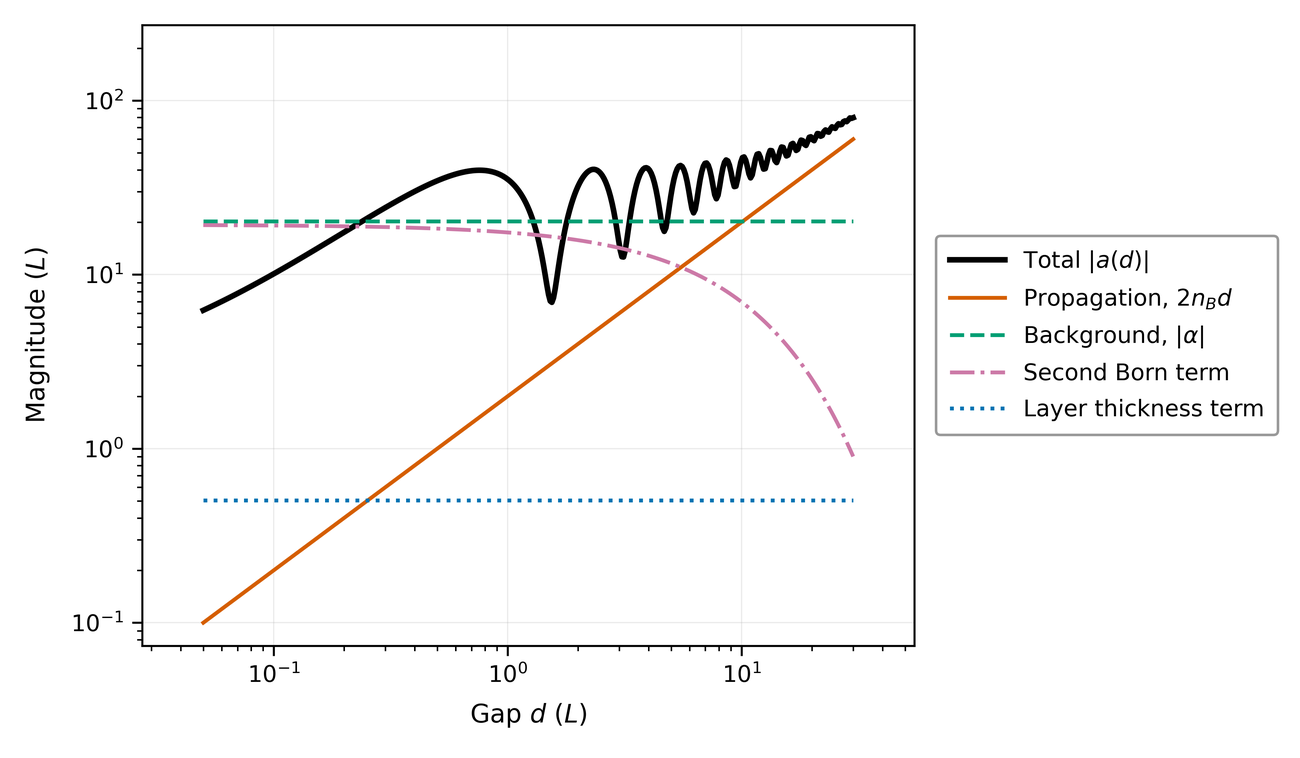

In [13]:
dd = np.geomspace(0.05, 30.0, 400)
parts_a = second_order_terms(dd, MU, N_R, ALPHA, L, LP, N_B)
total = sum(parts_a.values())
fig, ax = P.new_figure(legend=True)
ax.loglog(dd, np.abs(total), color=C["black"], lw=2.2, label=r"Total $|a(d)|$")
ax.loglog(dd, np.abs(parts_a["propagation"]), color=C["vermillion"], label=r"Propagation, $2n_Bd$")
ax.loglog(dd, np.abs(parts_a["background"]), "--", color=C["green"], label=r"Background, $|\alpha|$")
ax.loglog(dd, np.abs(parts_a["born"]), "-.", color=C["purple"], label="Second Born term")
ax.loglog(dd, np.abs(parts_a["layer"]), ":", color=C["blue"], label="Layer thickness term")
ax.set_ylim(0.1, 200)
P.label(ax, r"Gap $d$ ($L$)", r"Magnitude ($L$)")
P.legend_outside(fig, ax)
publish(fig, 8, "coefficient_terms", "analytic",
        r"Magnitudes of the four terms of the second-order coefficient, Eq. (14), for the $\mu = 4$ mode. "
        r"The background term $\alpha$ dominates below $d \approx |\alpha|/(2n_B) = 10\,L$ and the "
        r"propagation term beyond. The second Born term nearly cancels the background term at contact "
        r"and decays as $e^{-\gamma_f d}$.")
summary["coefficient_terms"] = {
    f"d{d:g}": {k: float(abs(v)) for k, v in second_order_terms(float(d), MU, N_R, ALPHA, L, LP, N_B).items()}
    | {"total": float(abs(second_order_coefficient(float(d), MU, N_R, ALPHA, L, LP, N_B)))}
    for d in (0.0, 8.0, 30.0)}
summary["coefficient_terms"]["crossover_d"] = float(abs(ALPHA) / (2 * N_B))

## 11. The error floor of the regularized scheme

In the limit $\delta \to 0$ the exact shift approaches the naive one, so Eq. (6) fixes the relative error of the regularized scheme, Eq. (18): $|1 - c\,e^{-\gamma_f d}|$, independent of $\delta$. At each gap we take the median error over the three smallest strengths as the measured floor and compare it with the law, and with its thin-layer form $|1 - e^{-\gamma_f d}|$.

{
 "c": [
  0.9948991132125257,
  -0.00033980214362449153
 ],
 "abs_c_minus_1": 0.005112192437246669,
 "ratio_median": 1.0001605910985534,
 "ratio_max_abs_dev": 0.028091399694725627,
 "thin_ratio_median_d_ge_1": 1.0073982273930513,
 "thin_max_abs_dev_d_ge_1": 0.03734865106631058,
 "thin_max_abs_dev_all": 1.0492447985539881,
 "floor_min": 0.01044390426145733,
 "floor_max": 0.9560477595910372,
 "floor_at_d_max": 0.9560477595910372,
 "flatness_max": 1.0469820158591434,
 "d_floor_10pct": 1.0310264590431586
}


**Fig. 9.** Small-strength limit of the regularized-scheme error for the $\mu = 4$ mode (median over $\delta \le 4.6\times10^{-4}$) against the floor law of Eq. (18), $|1 - ce^{-\gamma_f d}|$ with $|c - 1| = 5.11\times10^{-3}$, and its thin-layer form. The measured floor agrees with Eq. (18) to within $2.8\%$ at every gap.

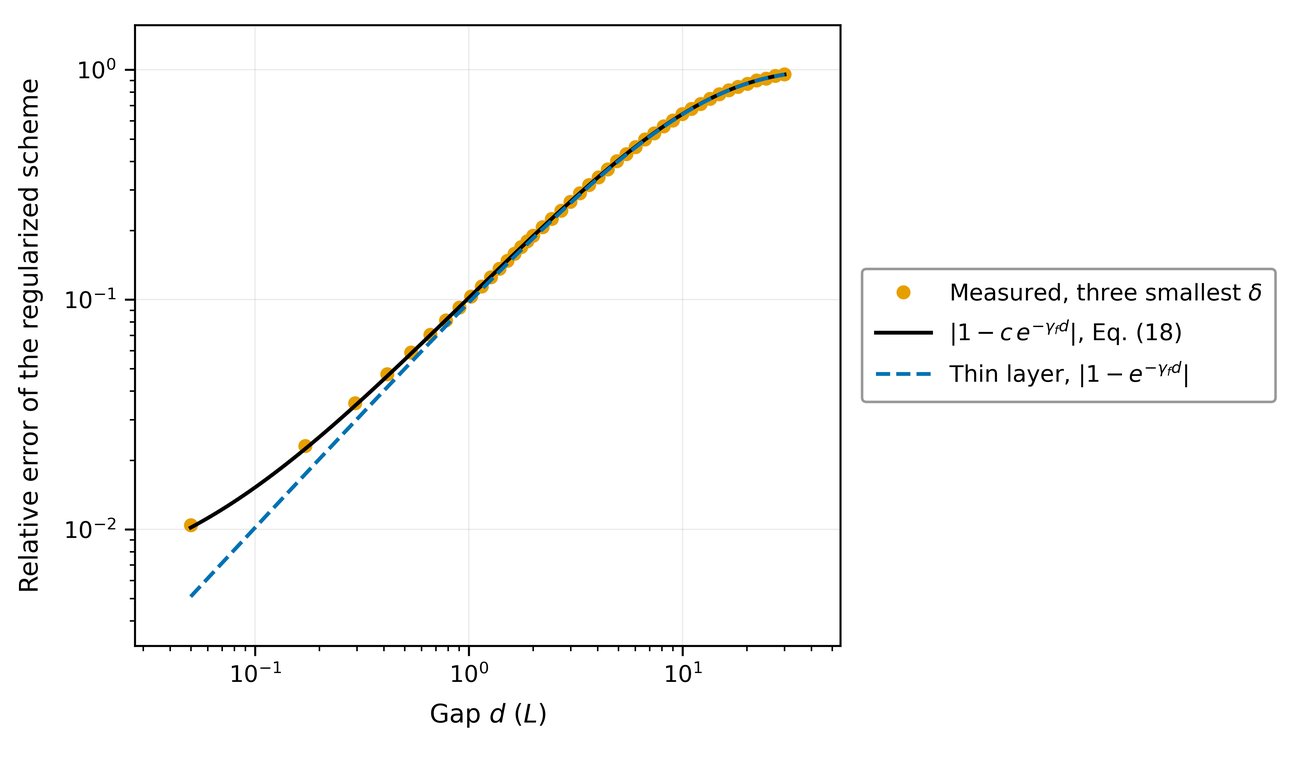

In [14]:
rows = []
for d, h in maps[maps.mu == MU].groupby("d"):
    smallest = h.nsmallest(3, "delta")
    rows.append({"d": d, "floor": smallest.err_reg.median(),
                 "flatness": smallest.err_reg.max() / smallest.err_reg.min(),
                 "law": float(regularization_floor(d, MU, N_R, L, LP, N_B)),
                 "law_thin_layer": float(regularization_floor(d, MU, N_R, L, LP, N_B, thin_layer=True))})
floor = pd.DataFrame(rows)
floor["ratio"] = floor.floor / floor.law
floor["ratio_thin_layer"] = floor.floor / floor.law_thin_layer
floor.to_csv(RESULTS / "regularized_floor.csv", index=False)
c_factor = (K0 * (np.exp(2j * N_B * K0.real * LP) - 1.0)) / (K0.real * (np.exp(2j * N_B * K0 * LP) - 1.0))
beyond = floor[floor.d >= 1.0]
summary["floor"] = {
    "c": [c_factor.real, c_factor.imag], "abs_c_minus_1": abs(c_factor - 1),
    "ratio_median": float(floor.ratio.median()), "ratio_max_abs_dev": float(np.max(np.abs(floor.ratio - 1))),
    "thin_ratio_median_d_ge_1": float(beyond.ratio_thin_layer.median()),
    "thin_max_abs_dev_d_ge_1": float(np.max(np.abs(beyond.ratio_thin_layer - 1))),
    "thin_max_abs_dev_all": float(np.max(np.abs(floor.ratio_thin_layer - 1))),
    "floor_min": float(floor.floor.min()), "floor_max": float(floor.floor.max()),
    "floor_at_d_max": float(floor.floor.iloc[-1]), "flatness_max": float(floor.flatness.max()),
    "d_floor_10pct": float(np.log(1 / 0.9) / GAMMA_F)}
print(json.dumps(summary["floor"], indent=1))

fig, ax = P.new_figure(legend=True)
ax.loglog(floor.d, floor.floor, "o", color=C["orange"], ms=4.5, label=r"Measured, three smallest $\delta$")
dense = np.geomspace(GAPS[0], GAPS[-1], 400)
ax.loglog(dense, regularization_floor(dense, MU, N_R, L, LP, N_B), color=C["black"],
          label=r"$|1 - c\,e^{-\gamma_f d}|$, Eq. (18)")
ax.loglog(dense, regularization_floor(dense, MU, N_R, L, LP, N_B, thin_layer=True), "--", color=C["blue"],
          label=r"Thin layer, $|1 - e^{-\gamma_f d}|$")
P.label(ax, r"Gap $d$ ($L$)", "Relative error of the regularized scheme")
P.legend_outside(fig, ax)
publish(fig, 9, "regularized_floor", "results/regularized_floor.csv",
        rf"Small-strength limit of the regularized-scheme error for the $\mu = 4$ mode (median over "
        rf"$\delta \le 4.6\times10^{{-4}}$) against the floor law of Eq. (18), $|1 - ce^{{-\gamma_f d}}|$ "
        rf"with $|c - 1| = {tex_sci(abs(c_factor - 1), 2)}$, and its thin-layer form. The measured floor agrees "
        rf"with Eq. (18) to within ${100 * summary['floor']['ratio_max_abs_dev']:.1f}\%$ at every gap.")

## 12. Scaling with perturbation strength

At a fixed gap, a scheme whose error is set by a second-order residual has a relative error proportional to $\delta$; the resummed scheme with the second Born term has a residual of third order, so its relative error scales as $\delta^2$; the regularized scheme is limited by its $\delta$-independent floor. Figures 10 and 11 show the strength dependence at $d = 0.54\,L$ and $d = 20\,L$. Exponents are slopes of $\ln(\text{error})$ against $\ln\delta$, for $\delta \le 0.1$ at the small gap and $\delta \le 2.2\times10^{-3}$ at the large gap, where $|a(d)F| < 0.25$.

**Fig. 10.** Relative error versus strength $\delta$ at $d = 0.54\,L$ for the $\mu = 4$ mode. The naive, self-consistent and resummed errors are proportional to $\delta$, the resummed error with the second Born term to $\delta^2$, and the regularized error is set by its floor.

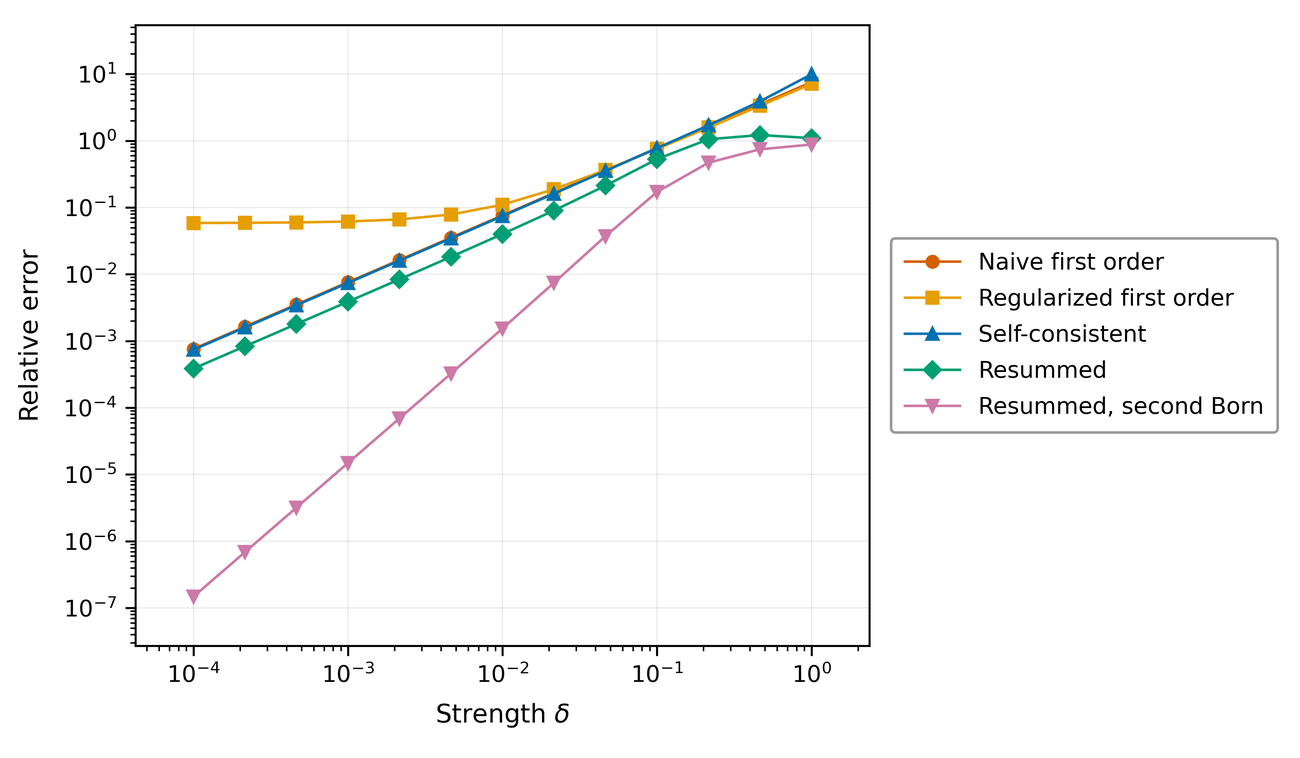

**Fig. 11.** As Fig. 10 at $d = 20.1\,L$. The errors of the naive and self-consistent schemes are larger than at small gaps by the growth of $|a(d)F|$, whereas the resummed errors are unchanged; beyond $\delta \approx 10^{-2}$ all single-mode schemes fail.

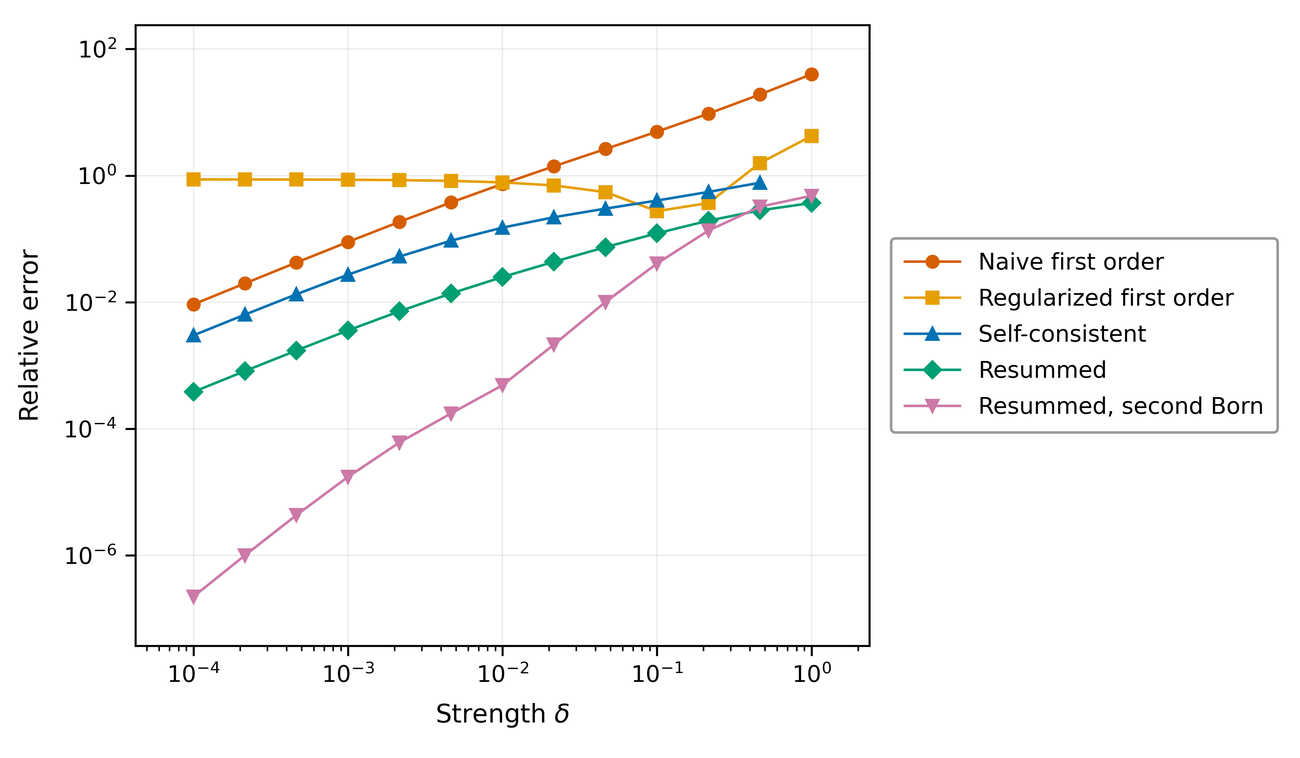

,near,far
naive,1.00242,0.97867
reg,0.34255,-0.00773
sc,1.00524,0.93595
res,1.03570,0.95655
res2,2.02245,1.83303


In [15]:
def strength_figure(d_target, number, name, delta_max, caption):
    d = GAPS[np.argmin(np.abs(GAPS - d_target))]
    h = maps[(maps.mu == MU) & (maps.d == d)].sort_values("delta")
    fit = h[h.delta <= delta_max * 1.0001]
    exponents = {}
    fig, ax = P.new_figure(legend=True)
    for key in ("naive", "reg", "sc", "res", "res2"):
        text, color, marker = STYLE[key]
        ok = h[np.isfinite(h["err_" + key])]
        ax.loglog(ok.delta, ok["err_" + key], marker + "-", color=color, ms=4.5, lw=1.0, label=text)
        sel = fit[np.isfinite(fit["err_" + key])]
        slope, _, sigma, _ = hac_linfit(np.log(sel.delta), np.log(sel["err_" + key]))
        exponents[key] = {"exponent": slope, "sigma": sigma}
    P.label(ax, r"Strength $\delta$", "Relative error")
    P.legend_outside(fig, ax)
    publish(fig, number, name, "results/shifts_and_errors.csv", caption.format(d=d))
    return float(d), exponents


d_near, exp_near = strength_figure(
    0.5, 10, "strength_near", 0.1,
    r"Relative error versus strength $\delta$ at $d = {d:.2f}\,L$ for the $\mu = 4$ mode. The naive, "
    r"self-consistent and resummed errors are proportional to $\delta$, the resummed error with the "
    r"second Born term to $\delta^2$, and the regularized error is set by its floor.")
d_far, exp_far = strength_figure(
    20.0, 11, "strength_far", 2.2e-3,
    r"As Fig. 10 at $d = {d:.1f}\,L$. The errors of the naive and self-consistent schemes are larger "
    r"than at small gaps by the growth of $|a(d)F|$, whereas the resummed errors are unchanged; beyond "
    r"$\delta \approx 10^{{-2}}$ all single-mode schemes fail.")
summary["strength_scaling"] = {"d_near": d_near, "near": exp_near, "d_far": d_far, "far": exp_far}
display(pd.DataFrame({"near": {k: v["exponent"] for k, v in exp_near.items()},
                      "far": {k: v["exponent"] for k, v in exp_far.items()}}))

## 13. Validity maps

Figures 12 to 15 map the relative error of the four schemes for the $\mu = 4$ mode over the $(d, \delta)$ plane. The black contour marks 10% error. Grey cells are points where the fixed-point iteration found no solution. Crosses mark cells in which the minimal-loss pole differs from the continued pole (Sec. 15); there the identity of the perturbed mode depends on the convention used to define it. Figure 16 collects the crossover gap $d_c(\delta)$ at which each scheme first exceeds 10% error.

**Fig. 12.** Relative error of the naive first-order scheme over the gap and strength plane ($\mu = 4$). The black contour marks 10% error; crosses mark cells where the minimal-loss and continued poles differ.

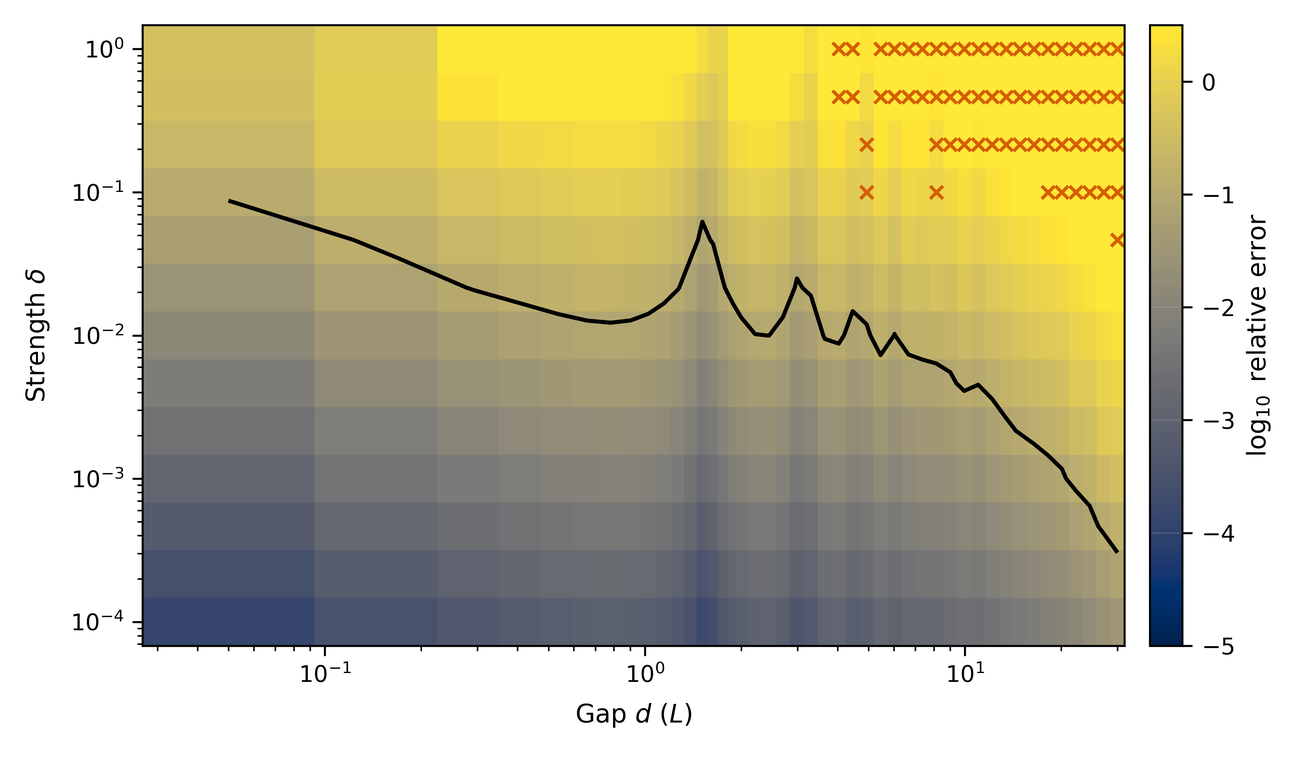

**Fig. 13.** As Fig. 12 for the regularized first-order scheme. Its error is bounded but exceeds 10% for every strength once $d \gtrsim 1\,L$.

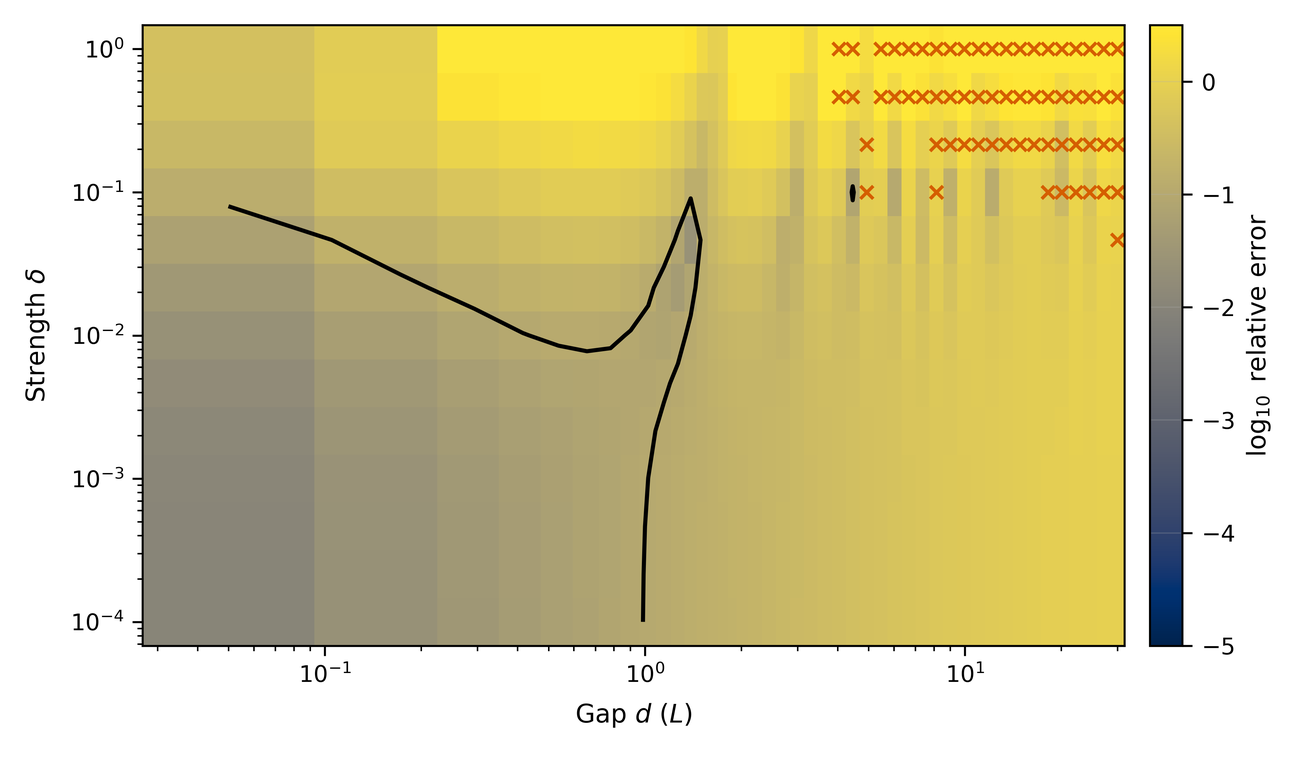

**Fig. 14.** As Fig. 12 for the self-consistent scheme. Grey cells: no fixed point found.

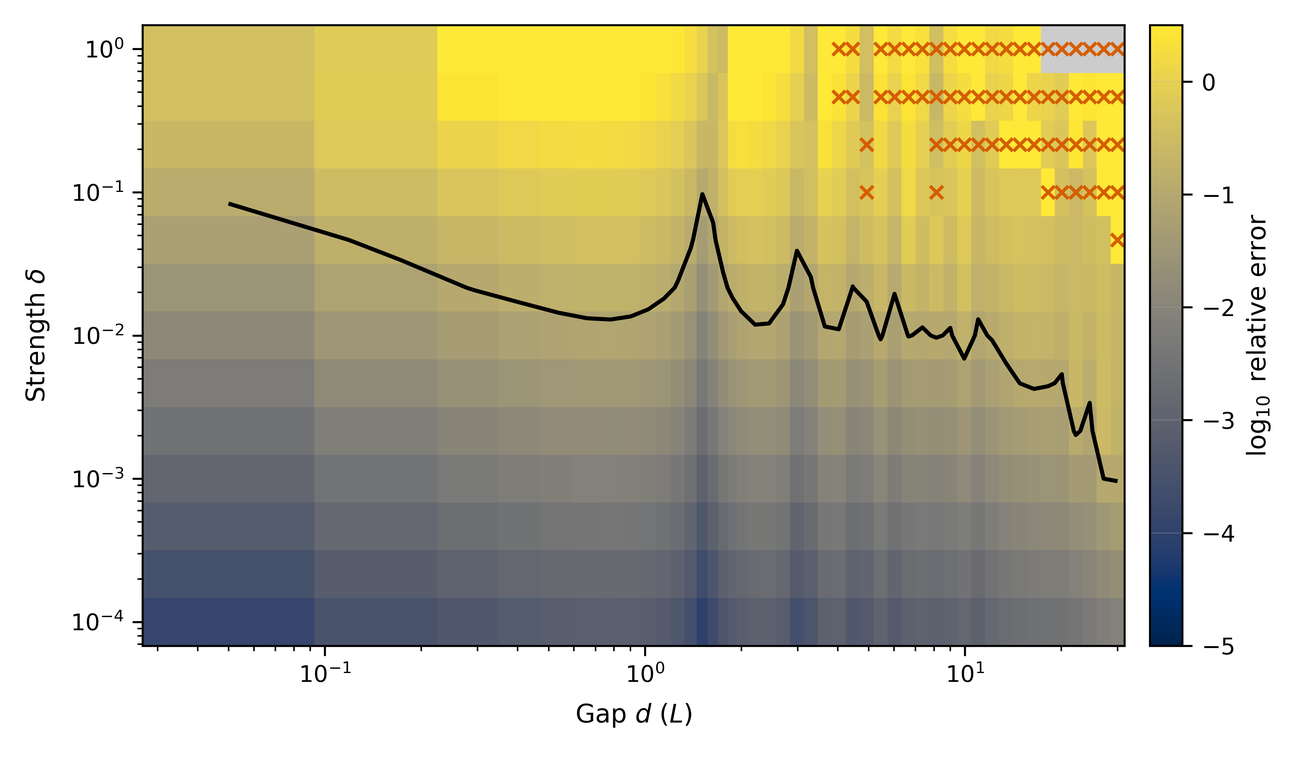

**Fig. 15.** As Fig. 12 for the resummed scheme with the exact background ratio $\alpha$. Grey cells: no fixed point found.

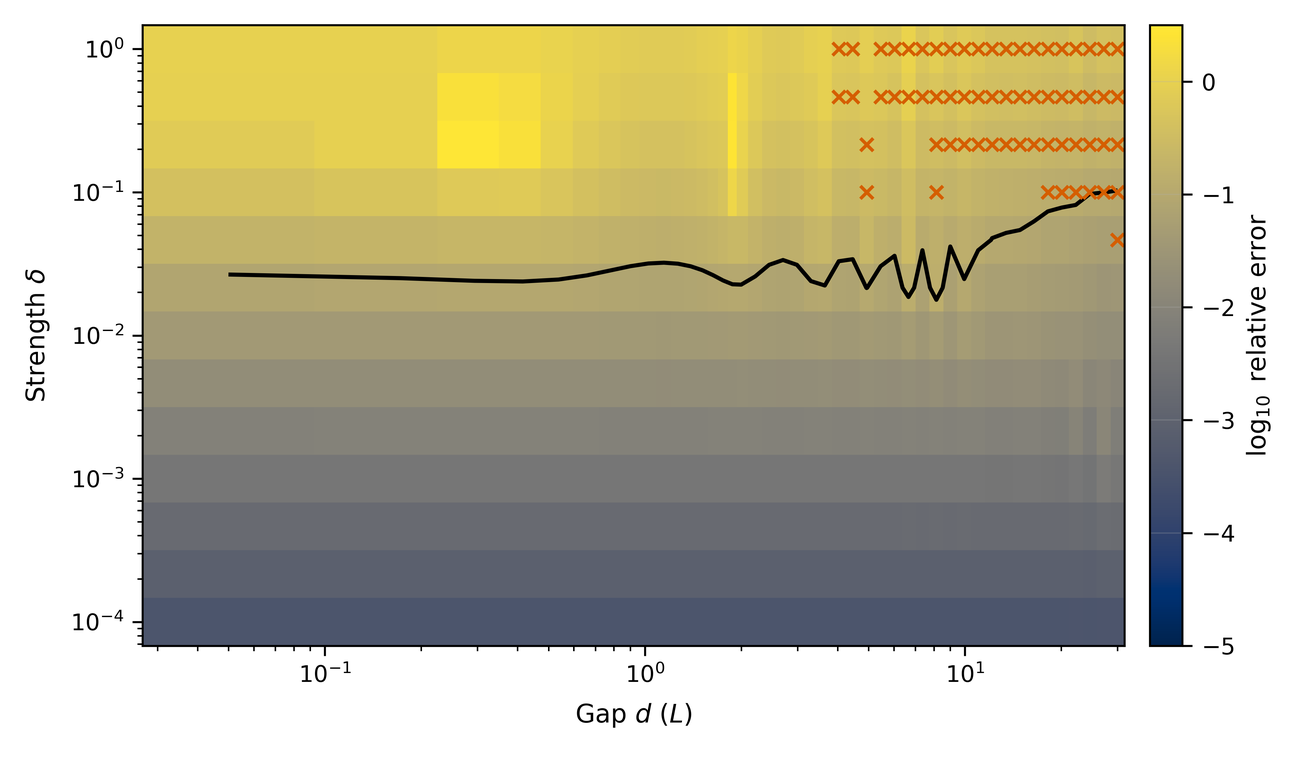

**Fig. 16.** Smallest gap $d_c$ at which each scheme exceeds 10% relative error, versus strength, for the $\mu = 4$ mode. A missing point means that the scheme stays below 10% on the whole grid ($d \le 30\,L$); a point at $d = 0.05\,L$ means it exceeds 10% already at the smallest gap.

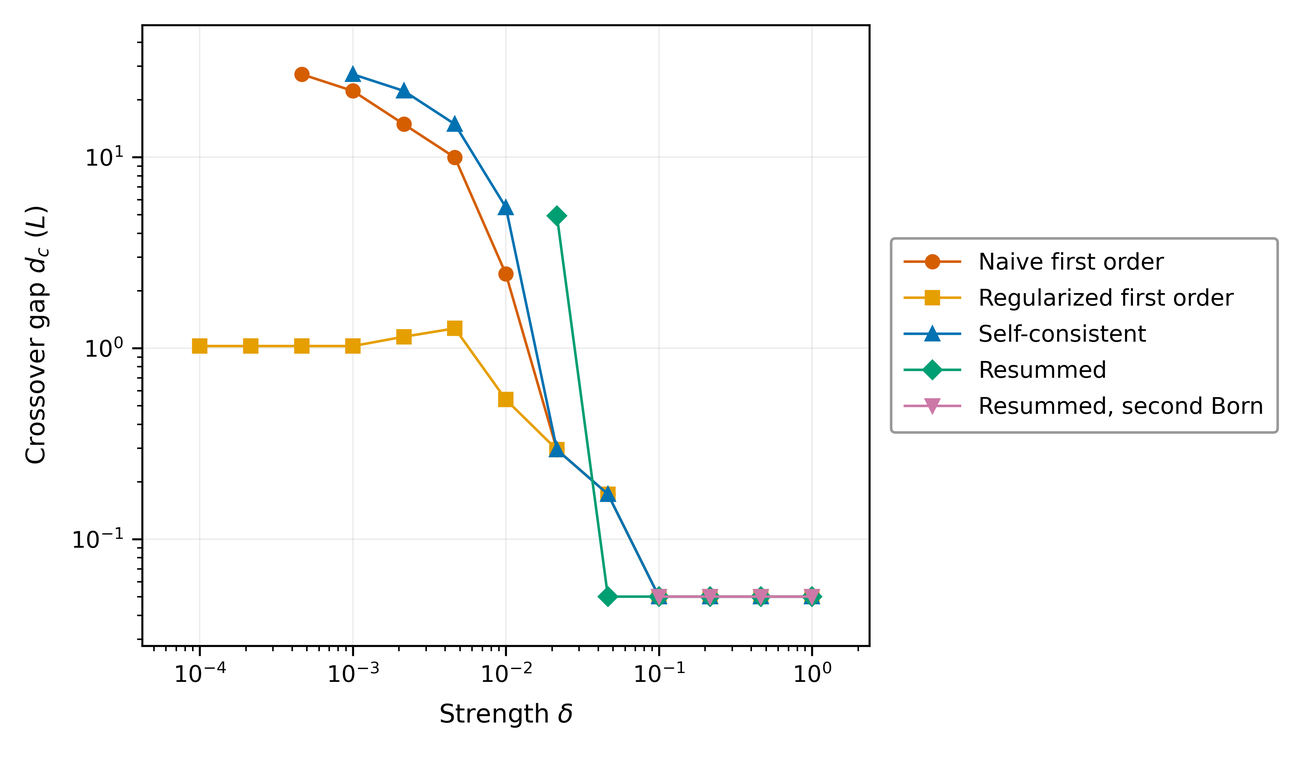

naive     0.47378
reg       0.11888
sc        0.51573
res       0.62937
res_cm    0.62413
res2      0.73077
Name: fraction of cells below 10%, dtype: float64

naive more accurate than regularized on 63.1% of cells; range over grid limits [0.5204545454545455, 0.6736596736596736]


In [16]:
def cell_edges(values):
    lv = np.log(np.asarray(values, dtype=float))
    mid = np.exp(0.5 * (lv[1:] + lv[:-1]))
    return np.concatenate([[np.exp(1.5 * lv[0] - 0.5 * lv[1])], mid, [np.exp(1.5 * lv[-1] - 0.5 * lv[-2])]])


AMBIGUOUS = identity[~identity.agree]


def error_map(key, number, caption):
    table = m4.pivot(index="delta", columns="d", values="err_" + key).sort_index()
    z = np.log10(table.values)
    fig, ax = P.new_figure(colorbar=True)
    ax.set_facecolor("0.8")
    ax.grid(False)
    mesh = ax.pcolormesh(cell_edges(table.columns), cell_edges(table.index), np.ma.masked_invalid(z),
                         cmap="cividis", vmin=-5.0, vmax=0.5, shading="flat")
    ax.contour(table.columns, table.index, np.where(np.isfinite(z), z, 1.0), levels=[-1.0],
               colors="black", linewidths=1.6, linestyles="solid")
    ax.plot(AMBIGUOUS.d, AMBIGUOUS.delta, "x", color=C["vermillion"], ms=5, mew=1.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    P.label(ax, r"Gap $d$ ($L$)", r"Strength $\delta$", pad_frac=0)
    P.colorbar_outside(fig, ax, mesh, r"$\log_{10}$ relative error")
    publish(fig, number, f"map_{key}", "results/shifts_and_errors.csv", caption)


error_map("naive", 12, r"Relative error of the naive first-order scheme over the gap and strength plane "
          r"($\mu = 4$). The black contour marks 10% error; crosses mark cells where the minimal-loss and "
          r"continued poles differ.")
error_map("reg", 13, r"As Fig. 12 for the regularized first-order scheme. Its error is bounded but "
          r"exceeds 10% for every strength once $d \gtrsim 1\,L$.")
error_map("sc", 14, r"As Fig. 12 for the self-consistent scheme. Grey cells: no fixed point found.")
error_map("res", 15, r"As Fig. 12 for the resummed scheme with the exact background ratio $\alpha$. "
          r"Grey cells: no fixed point found.")

rows = []
for key in ("naive", "reg", "sc", "res", "res2"):
    for delta, h in m4.groupby("delta"):
        h = h.sort_values("d")
        bad = h[~(h["err_" + key] <= 0.1)]
        rows.append({"scheme": key, "delta": delta, "d_c": float(bad.d.iloc[0]) if len(bad) else np.inf})
crossover = pd.DataFrame(rows)
crossover.to_csv(RESULTS / "crossover.csv", index=False)

fig, ax = P.new_figure(legend=True)
for key in ("naive", "reg", "sc", "res", "res2"):
    text, color, marker = STYLE[key]
    h = crossover[(crossover.scheme == key) & np.isfinite(crossover.d_c)]
    ax.loglog(h.delta, h.d_c, marker + "-", color=color, ms=5, lw=1.0, label=text)
P.label(ax, r"Strength $\delta$", r"Crossover gap $d_c$ ($L$)")
P.legend_outside(fig, ax)
publish(fig, 16, "crossover", "results/crossover.csv",
        r"Smallest gap $d_c$ at which each scheme exceeds 10% relative error, versus strength, for the "
        r"$\mu = 4$ mode. A missing point means that the scheme stays below 10% on the whole grid "
        r"($d \le 30\,L$); a point at $d = 0.05\,L$ means it exceeds 10% already at the smallest gap.")

sensitivity = {}
for d_max in (10.0, 20.0, 30.0):
    for delta_min in (1e-4, 1e-3):
        sel = m4[(m4.d <= d_max) & (m4.delta >= delta_min * 0.999)]
        sensitivity[f"d<={d_max:g}, delta>={delta_min:g}"] = float((sel.err_naive < sel.err_reg).mean())
summary["maps"] = {
    "fraction_error_below_10pct": {k: float((m4["err_" + k] <= 0.1).mean())
                                   for k in ("naive", "reg", "sc", "res", "res_cm", "res2")},
    "naive_better_than_regularized": float((m4.err_naive < m4.err_reg).mean()),
    "naive_better_sensitivity": sensitivity,
    "naive_better_range": [min(sensitivity.values()), max(sensitivity.values())],
    "crossover": {key: {f"{row.delta:.3g}": row.d_c for row in crossover[crossover.scheme == key].itertuples()}
                  for key in ("naive", "reg", "sc", "res", "res2")},
    "ambiguous_cells": int(len(AMBIGUOUS)), "cells": int(len(m4))}
display(pd.Series(summary["maps"]["fraction_error_below_10pct"], name="fraction of cells below 10%"))
print(f"naive more accurate than regularized on {summary['maps']['naive_better_than_regularized']:.1%} of cells; "
      f"range over grid limits {summary['maps']['naive_better_range']}")

## 14. Scope: quality factor and perturber geometry

**Quality factor.** Three cavities, $n_R = 4$, $2\pi$ and 15, span a factor 14 in $\gamma_f$. For each, the gap runs from $0.5\,L$ to six field decay lengths, $6/\gamma_f$, and the strength is chosen so that $|a(d)F| = 0.01$ at the largest gap, which keeps every point in the regime where third-order terms stay below about $1\%$. Rates are fitted on $\gamma_f d \ge 1.5$.

**Perturber geometry.** Layer thicknesses from $0.02\,L$ to $0.5\,L$, with positive and negative permittivity change, at $\delta = 10^{-5}$ and gaps from $0.5\,L$ to $30\,L$. Equation (14) depends on the thickness through the layer and second Born terms.

,0,1,2
n_R,4.0,6.28319,15.0
Q,12.30006,19.5714,47.05399
gamma_f,0.25541,0.10219,0.0178
alpha_im,8.5,20.23921,113.0
d_max,23.49138,58.7142,336.99941
decay_lengths,6.0,6.0,6.0
delta,0.0,0.0,0.0
continuation_ok,True,True,True
points_in_window,25,21,15
exact_rate_over_gamma_f,1.0001,1.00017,0.99892


quality-factor campaign in 0.1 s


**Fig. 17.** Absolute error of the naive scheme divided by the second-order prediction $|a(d)F^2|$, versus the gap in units of the field decay length, for three cavities spanning a factor 14 in $\gamma_f$. Each strength is chosen so that $|a(d)F| = 0.01$ at the largest gap.

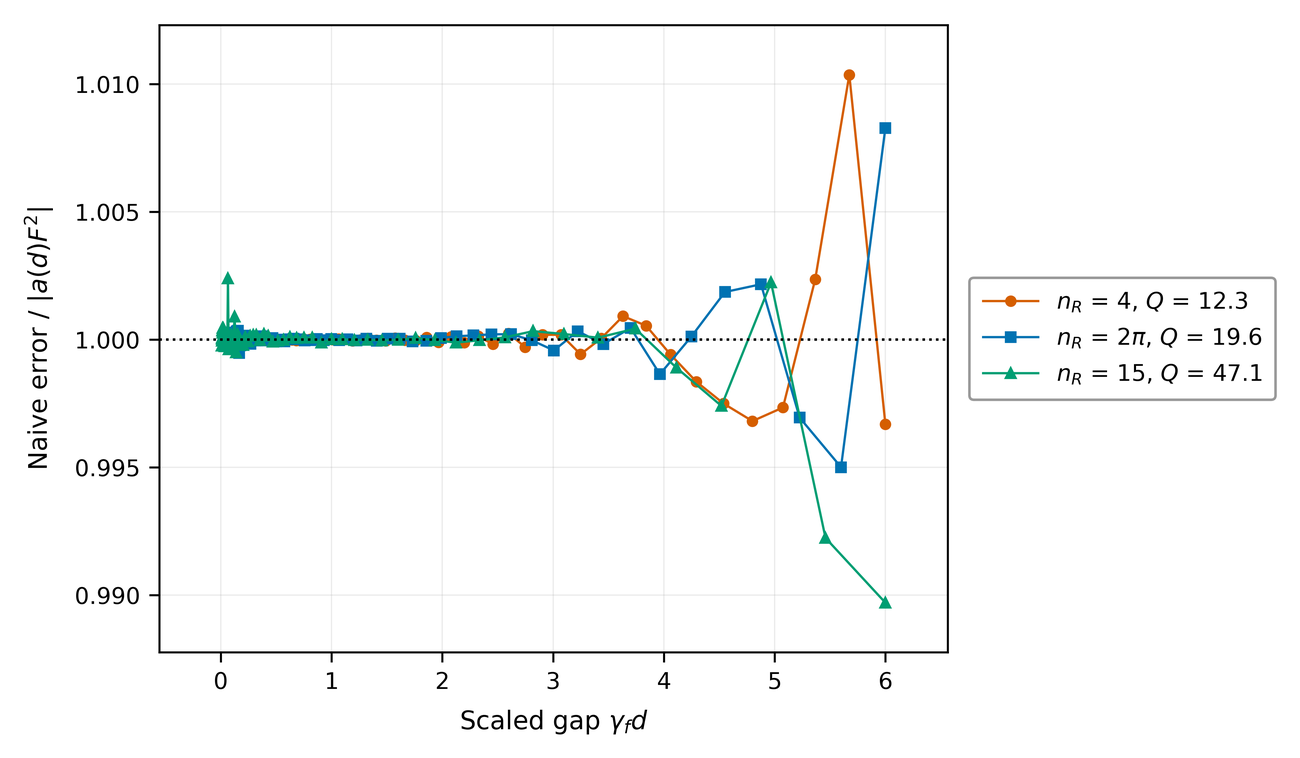

In [17]:
t0 = time.time()
rows, curves = [], {}
for n_r in (4.0, N_R, 15.0):
    k0 = slab_wavenumber(MU, n_r, L, N_B)
    gf = 2 * N_B * abs(k0.imag)
    alpha_c = slab_background_ratio(n_r, L, N_B)
    gaps_c = np.geomspace(0.5, 6.0 / gf, 70)
    a_max = abs(second_order_coefficient(gaps_c[-1], MU, n_r, alpha_c, L, LP, N_B))
    delta_c = 0.01 / (a_max * abs(first_order(MU, gaps_c[-1], 1.0, n_r)))
    roots, ok = exact_at(MU, delta_c, gaps_c, n_r)
    shift = roots - k0
    f_c = np.array([first_order(MU, d, delta_c, n_r) for d in gaps_c])
    coeff = second_order_coefficient(gaps_c, MU, n_r, alpha_c, L, LP, N_B)
    err_abs = np.abs(f_c - shift)
    ratio = err_abs / np.abs(coeff * f_c**2)
    res = np.array([solve_shift(MU, d, contrast(delta_c, n_r), n_r, alpha_c, None, L, LP, N_B)[0] for d in gaps_c])
    err_res = np.abs(res - shift) / np.abs(shift)
    win = gaps_c * gf >= 1.5
    ex = hac_linfit(gaps_c[win], np.log(np.abs(shift[win])))
    cor = hac_linfit(gaps_c[win], np.log(err_abs[win] / np.abs(coeff[win])))
    raw = hac_linfit(gaps_c[win], np.log(err_abs[win]))
    rows.append({"n_R": n_r, "Q": k0.real / (2 * abs(k0.imag)), "gamma_f": gf, "alpha_im": alpha_c.imag,
                 "d_max": gaps_c[-1], "decay_lengths": gaps_c[-1] * gf, "delta": delta_c,
                 "continuation_ok": ok, "points_in_window": int(win.sum()),
                 "exact_rate_over_gamma_f": ex[0] / gf, "exact_sigma_over_gamma_f": ex[2] / gf,
                 "corrected_rate_over_2gamma_f": cor[0] / (2 * gf), "corrected_sigma_over_2gamma_f": cor[2] / (2 * gf),
                 "raw_rate_over_2gamma_f": raw[0] / (2 * gf),
                 "ratio_median": np.median(ratio[win]), "ratio_min": ratio[win].min(), "ratio_max": ratio[win].max(),
                 "resummed_error_median": np.median(err_res),
                 "resummed_error_predicted": resummed_error_per_delta(MU, n_r) * delta_c})
    curves[n_r] = (gaps_c * gf, ratio)
cavities = pd.DataFrame(rows)
cavities.to_csv(RESULTS / "cavities.csv", index=False)
display(cavities.T)
print(f"quality-factor campaign in {time.time() - t0:.1f} s")
summary["cavities"] = cavities.to_dict(orient="records")

fig, ax = P.new_figure(legend=True)
for (n_r, (x_c, ratio)), color, marker in zip(curves.items(), (C["vermillion"], C["blue"], C["green"]), "os^"):
    q = cavities[cavities.n_R == n_r].Q.iloc[0]
    name = r"$2\pi$" if np.isclose(n_r, N_R) else f"{n_r:g}"
    ax.plot(x_c, ratio, marker + "-", color=color, ms=3.5, lw=0.9, label=rf"$n_R$ = {name}, $Q$ = {q:.1f}")
ax.axhline(1.0, color=C["black"], lw=1.0, ls=":")
P.label(ax, r"Scaled gap $\gamma_f d$", r"Naive error / $|a(d)F^2|$")
P.legend_outside(fig, ax)
publish(fig, 17, "cavities", "results/cavities.csv",
        r"Absolute error of the naive scheme divided by the second-order prediction $|a(d)F^2|$, versus "
        r"the gap in units of the field decay length, for three cavities spanning a factor 14 in "
        r"$\gamma_f$. Each strength is chosen so that $|a(d)F| = 0.01$ at the largest gap.")

,L_p,sign,continuation_ok,ratio_median,ratio_min,ratio_max,corrected_rate_over_2gamma_f,sigma,sc_gain_median_far,res_gain_median_far,res_error_median,res_error_max_over_min,res_error_predicted
0,0.02,1,True,1.00000,0.99950,1.00060,1.00009,0.00005,2.71501,14.09177,7.70163e-06,1.00076,7.70150e-06
1,0.02,-1,True,1.00000,0.99940,1.00050,0.99991,0.00005,2.71466,14.09004,7.70150e-06,1.00075,7.70150e-06
2,0.05,1,True,0.99999,0.99877,1.00161,1.00023,0.00014,2.72904,14.05024,1.92727e-05,1.00183,1.92726e-05
3,0.05,-1,True,1.00000,0.99839,1.00123,0.99977,0.00014,2.72821,14.04634,1.92726e-05,1.00183,1.92726e-05
4,0.10,1,True,1.00000,0.99764,1.00359,1.00048,0.00029,2.75271,13.93073,3.86430e-05,1.00339,3.86428e-05
5,0.10,-1,True,1.00001,0.99642,1.00238,0.99952,0.00029,2.75117,13.92343,3.86426e-05,1.00339,3.86428e-05
6,0.20,1,True,0.99999,0.99582,1.00840,1.00099,0.00062,2.80168,13.50520,7.79459e-05,1.00706,7.79464e-05
7,0.20,-1,True,1.00001,0.99172,1.00421,0.99901,0.00062,2.79920,13.49319,7.79469e-05,1.00704,7.79464e-05
8,0.50,1,True,0.99993,0.99597,1.02254,1.00199,0.00153,2.97637,10.87422,2.06303e-04,1.01709,2.06316e-04
9,0.50,-1,True,1.00007,0.97859,1.00392,0.99804,0.00148,2.97636,10.86623,2.06328e-04,1.01633,2.06316e-04


geometry campaign in 0.2 s


**Fig. 18.** Absolute error of the naive scheme divided by the second-order prediction $|a(d)F^2|$ of Eq. (13) for five layer thicknesses and both signs of the permittivity change ($\mu = 4$, $\delta = 10^{-5}$).

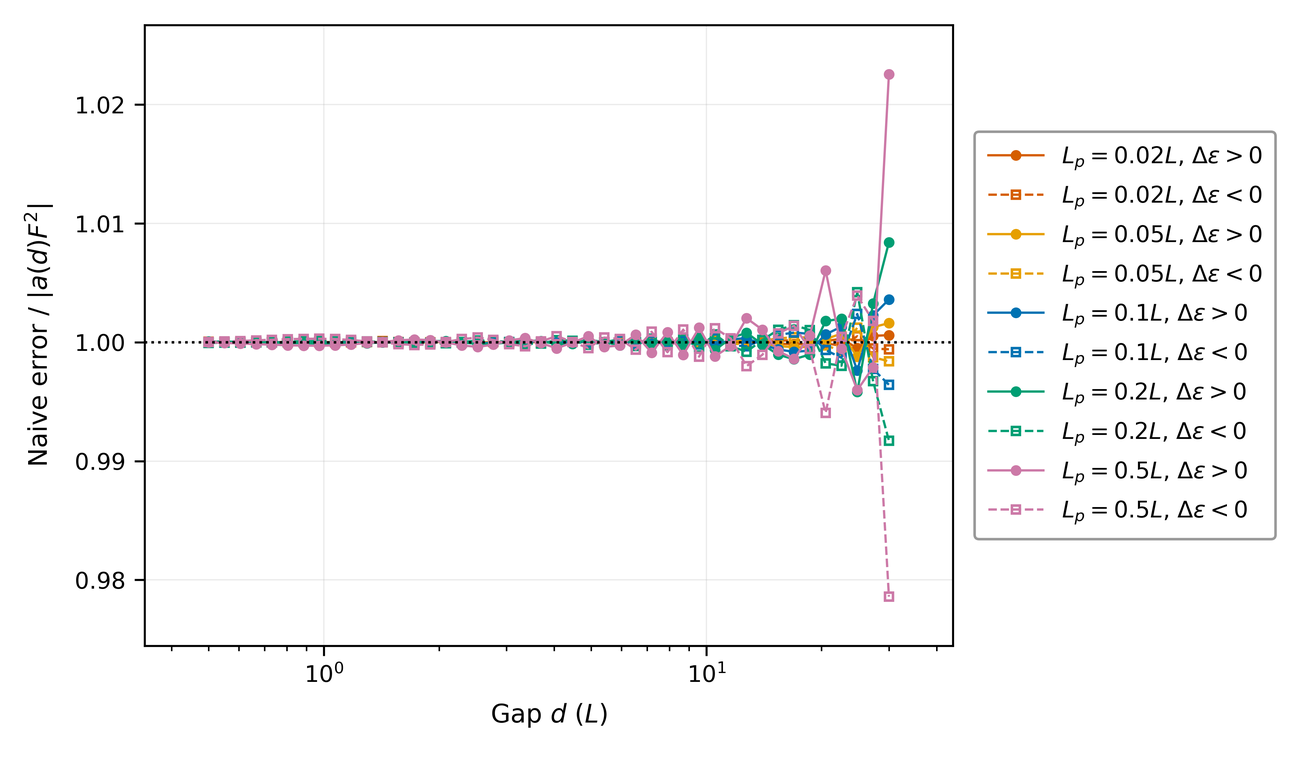

In [18]:
t0 = time.time()
DELTA_GEO = 1e-5
gaps_g = np.geomspace(0.5, 30.0, 44)
rows, curves_g = [], {}
for lp in (0.02, 0.05, 0.1, 0.2, 0.5):
    for sign in (1.0, -1.0):
        roots, ok = exact_at(MU, DELTA_GEO, gaps_g, N_R, lp, sign)
        shift = roots - K0
        f_g = np.array([first_order(MU, d, DELTA_GEO, N_R, lp, sign) for d in gaps_g])
        coeff = second_order_coefficient(gaps_g, MU, N_R, ALPHA, L, lp, N_B)
        err_abs = np.abs(f_g - shift)
        ratio = err_abs / np.abs(coeff * f_g**2)
        sc_v, sc_ok = scheme_track(MU, DELTA_GEO, gaps_g, 0.0, N_R, lp, sign)
        res_v, res_ok = scheme_track(MU, DELTA_GEO, gaps_g, ALPHA, N_R, lp, sign)
        err_n, err_sc = err_abs / np.abs(shift), np.abs(sc_v - shift) / np.abs(shift)
        err_res = np.abs(res_v - shift) / np.abs(shift)
        far_g, beyond_g = gaps_g >= 8.0, gaps_g >= 1.0
        cor = hac_linfit(gaps_g[far_g], np.log(err_abs[far_g] / np.abs(coeff[far_g])))
        rows.append({"L_p": lp, "sign": int(sign), "continuation_ok": ok,
                     "ratio_median": np.median(ratio[beyond_g]), "ratio_min": ratio[beyond_g].min(),
                     "ratio_max": ratio[beyond_g].max(),
                     "corrected_rate_over_2gamma_f": cor[0] / (2 * GAMMA_F), "sigma": cor[2] / (2 * GAMMA_F),
                     "sc_gain_median_far": np.median(err_n[far_g] / err_sc[far_g]),
                     "res_gain_median_far": np.median(err_n[far_g] / err_res[far_g]),
                     "res_error_median": np.median(err_res), "res_error_max_over_min": err_res.max() / err_res.min(),
                     "res_error_predicted": resummed_error_per_delta(MU, N_R, lp) * DELTA_GEO})
        curves_g[(lp, sign)] = ratio
geometry = pd.DataFrame(rows)
geometry.to_csv(RESULTS / "geometry.csv", index=False)
display(geometry)
print(f"geometry campaign in {time.time() - t0:.1f} s")
summary["geometry"] = geometry.to_dict(orient="records")

palette = [C["vermillion"], C["orange"], C["blue"], C["green"], C["purple"]]
fig, ax = P.new_figure(legend=True)
for i, lp in enumerate((0.02, 0.05, 0.1, 0.2, 0.5)):
    ax.plot(gaps_g, curves_g[(lp, 1.0)], "o-", color=palette[i], ms=3.2, lw=0.9,
            label=rf"$L_p = {lp:g}L$, $\Delta\varepsilon > 0$")
    ax.plot(gaps_g, curves_g[(lp, -1.0)], "s--", color=palette[i], ms=3.2, lw=0.9, mfc="none",
            label=rf"$L_p = {lp:g}L$, $\Delta\varepsilon < 0$")
ax.axhline(1.0, color=C["black"], lw=1.0, ls=":")
ax.set_xscale("log")
P.label(ax, r"Gap $d$ ($L$)", r"Naive error / $|a(d)F^2|$")
P.legend_outside(fig, ax, ncol=1)
publish(fig, 18, "geometry", "results/geometry.csv",
        r"Absolute error of the naive scheme divided by the second-order prediction $|a(d)F^2|$ of Eq. (13) for five "
        r"layer thicknesses and both signs of the permittivity change ($\mu = 4$, $\delta = 10^{-5}$).")

## 15. Mode identity at large gaps

Figure 19 shows, for $\delta = 10^{-3}$ and $\delta = 0.1$, the distance from the continued pole to the nearest competing pole in units of the shift, and marks the gaps at which the minimal-loss criterion selects a different pole.

**Fig. 19.** Distance from the continued $\mu = 4$ pole to the nearest other pole within $0.45\,L^{-1}$, in units of the shift, for $\delta = 10^{-3}$ and $0.1$. Open symbols mark gaps where the pole with the smallest loss is not the continued pole.

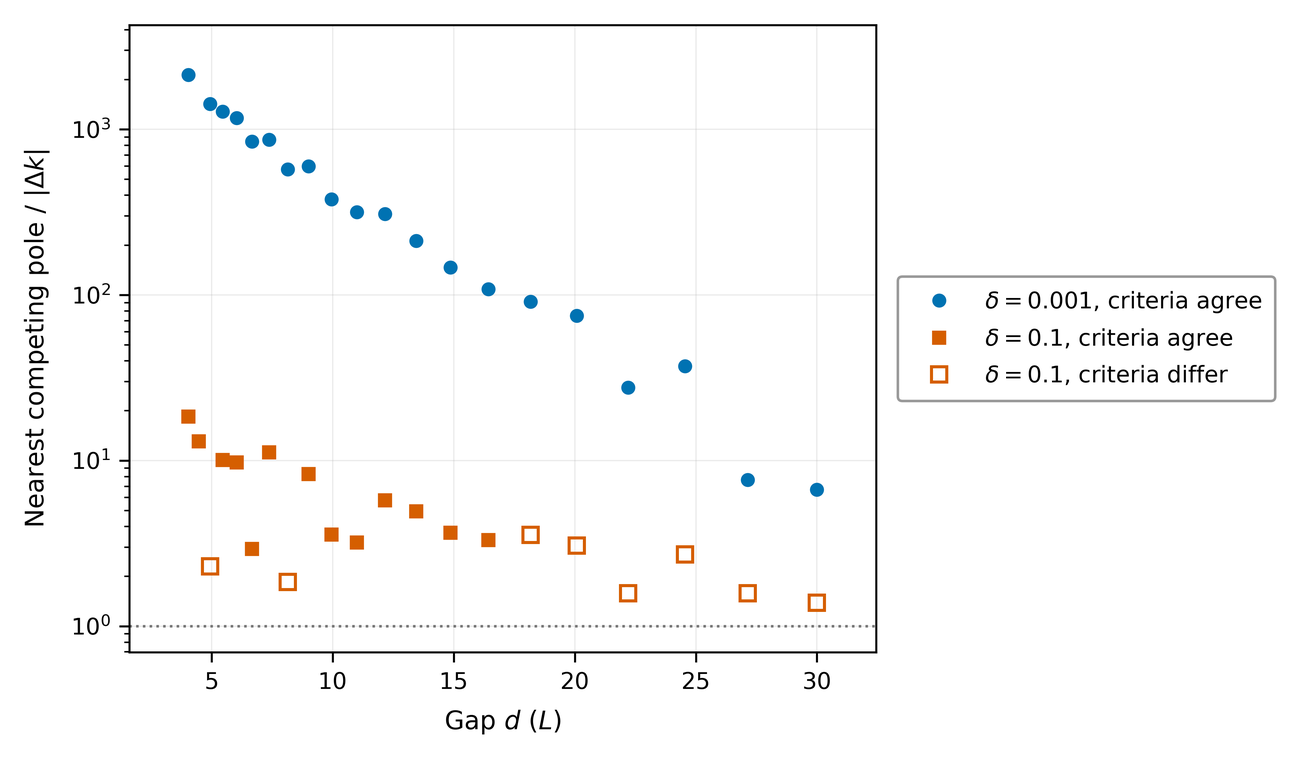

,cells,disagree,min_margin
delta,,,
0.00010,21,0,161.86803
0.00022,21,0,58.87747
0.00046,21,0,19.66723
0.00100,21,0,6.65537
0.00215,21,0,2.52299
0.00464,21,0,3.28669
0.01000,21,0,2.73545
0.02154,21,0,2.02097
0.04642,21,1,1.68189


{
 "cells": 273,
 "disagree": 64,
 "delta_1e-3": {
  "cells": 21,
  "disagree": 0,
  "min_margin": 6.655374178971976
 },
 "delta_0.1": {
  "cells": 21,
  "disagree": 8,
  "min_margin": 1.3848486641087094
 },
 "smallest_delta_with_disagreement": 0.046415888336127774
}


In [19]:
fig, ax = P.new_figure(legend=True)
for delta, color, marker in ((1e-3, C["blue"], "o"), (0.1, C["vermillion"], "s")):
    h = identity[np.isclose(identity.delta, delta)]
    agree, disagree = h[h.agree], h[~h.agree]
    ax.semilogy(agree.d, agree.margin, marker, color=color, ms=4.5, label=rf"$\delta = {delta:g}$, criteria agree")
    if len(disagree):
        ax.semilogy(disagree.d, disagree.margin, marker, color=color, ms=6, mfc="none", mew=1.2,
                    label=rf"$\delta = {delta:g}$, criteria differ")
ax.axhline(1.0, color=C["grey"], lw=1.0, ls=":")
P.label(ax, r"Gap $d$ ($L$)", r"Nearest competing pole / $|\Delta k|$")
P.legend_outside(fig, ax)
publish(fig, 19, "mode_identity", "results/identity.csv",
        r"Distance from the continued $\mu = 4$ pole to the nearest other pole within $0.45\,L^{-1}$, in "
        r"units of the shift, for $\delta = 10^{-3}$ and $0.1$. Open symbols mark gaps where the pole with "
        r"the smallest loss is not the continued pole.")

by_delta = identity.groupby("delta").agg(cells=("agree", "size"), disagree=("agree", lambda s: int((~s).sum())),
                                         min_margin=("margin", "min"))
display(by_delta)
def identity_at(delta):
    row = by_delta.iloc[int(np.argmin(np.abs(by_delta.index.values - delta)))]
    return {"cells": int(row.cells), "disagree": int(row.disagree), "min_margin": float(row.min_margin)}


summary["identity"] = {
    "cells": int(len(identity)), "disagree": int((~identity.agree).sum()),
    "delta_1e-3": identity_at(1e-3), "delta_0.1": identity_at(0.1),
    "smallest_delta_with_disagreement": float(identity[~identity.agree].delta.min()) if (~identity.agree).any() else None}
print(json.dumps(summary["identity"], indent=1))

## 16. Resonant-state expansion

The RSE represents the perturbed structure in the resonant states of a homogeneous basis slab. A layer outside the basis slab cannot be represented, so the basis slab is made wide enough to contain the cavity, the gap and the layer: its width is $W = m(L + d + L_p)$ with margin $m = 1.2$ or $1.5$, and its permittivity is $\varepsilon_s = n_R^2$ or $n_R$. The cavity, gap, layer and margin regions enter as piecewise-constant perturbations of the basis slab. We compare the RSE eigenvalue nearest to the exact pole for basis sizes $N = 25$ to 401 at seven gaps and four strengths (112 configurations), fit the convergence exponent of each configuration, and extend the four hardest cases to $N = 1201$ to find the basis size at which the target relative error of $10^{-6}$, fixed before the production runs for $N = 401$, is reached.

560 RSE eigenproblems in 42.7 s
{
 "configurations": 112,
 "monotone_fraction": 1.0,
 "best_exponent_median": -3.2358600430707116,
 "best_exponent_range": [
  -4.057254956353231,
  -3.0445995058678244
 ],
 "best_error_401_median": 1.0383324527322658e-06,
 "best_error_401_worst": 8.086085669616532e-06,
 "fraction_best_below_1e-6": 0.42857142857142855,
 "basis_of_best": {
  "n_R^2": 28
 },
 "margin_of_best": {
  "1.2": 28
 },
 "best_error_401_by_gap": {
  "0.1": [
   1.5461705045394964e-07,
   1.6823477633400228e-07
  ],
  "0.25": [
   1.9732920731210108e-07,
   2.8386984193874075e-07
  ],
  "0.5": [
   4.613003573888469e-07,
   5.545666440157449e-07
  ],
  "1": [
   1.0155687924438594e-06,
   1.0425766721417267e-06
  ],
  "1.5": [
   1.4174841816817227e-06,
   1.8819867040743176e-06
  ],
  "2": [
   3.119747063500347e-06,
   3.478709357281869e-06
  ],
  "3": [
   5.629529097435769e-06,
   8.086085669616532e-06
  ]
 },
 "largest_gap_target_met_401": 0.5
}


**Fig. 20.** Relative error of the embedding-basis RSE pole versus basis size at $d = 0.5\,L$ for four strengths ($\mu = 4$), each with the basis permittivity and margin that give the smallest error at $N = 401$. The dotted line shows $N^{-3}$ for reference.

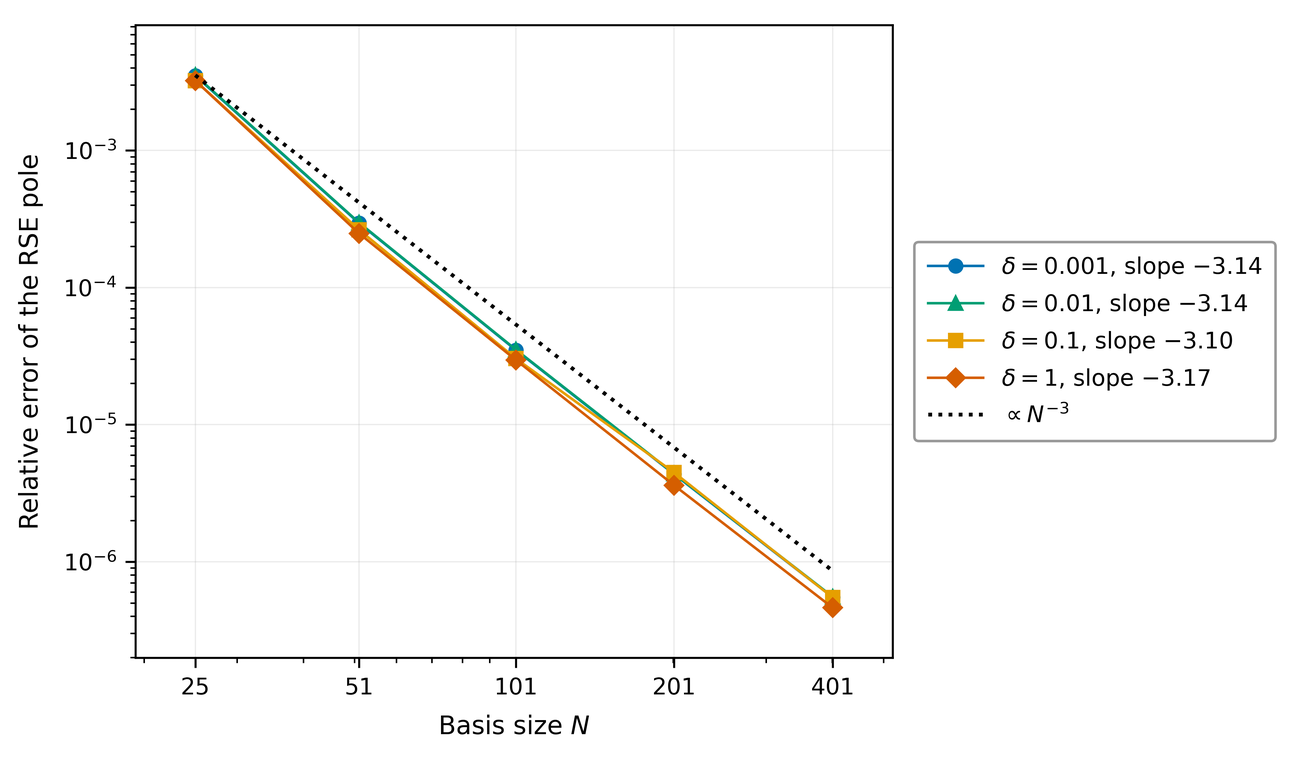

In [20]:
RSE_GAPS, RSE_DELTAS, RSE_N = (0.1, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0), (1e-3, 1e-2, 1e-1, 1.0), (25, 51, 101, 201, 401)
EPS_BASIS = {"n_R^2": N_R**2, "n_R": N_R}


def rse_pieces(d, delta, margin, eps_s):
    a = margin * (L + d + LP) / 2.0
    z = [-a, -a + L, -a + L + d, -a + L + d + LP, a]
    values = [N_R**2, N_B**2, N_B**2 + contrast(delta), N_B**2]
    return a, [(z[i], z[i + 1], values[i] - eps_s) for i in range(4)]


exact_rse = {}
for delta in RSE_DELTAS:
    roots, _ = exact_at(MU, delta, np.array(RSE_GAPS))
    exact_rse.update({(d, delta): k for d, k in zip(RSE_GAPS, roots)})

t0 = time.time()
rows = []
for (d, delta), k_ex in exact_rse.items():
    for margin in (1.2, 1.5):
        for tag, eps_s in EPS_BASIS.items():
            a, pieces = rse_pieces(d, delta, margin, eps_s)
            for n_basis in RSE_N:
                k_rse = nearest(rse_wavenumbers((n_basis - 1) // 2, eps_s, a, pieces), k_ex)
                rows.append({"d": d, "delta": delta, "margin": margin, "basis": tag, "N": n_basis,
                             "rel_error": abs(k_rse - k_ex) / abs(k_ex)})
rse = pd.DataFrame(rows)
rse.to_csv(RESULTS / "rse.csv", index=False)
print(f"{len(rse)} RSE eigenproblems in {time.time() - t0:.1f} s")

rows = []
for (d, delta, margin, tag), h in rse.groupby(["d", "delta", "margin", "basis"]):
    h = h.sort_values("N")
    slope, _, sigma, _ = hac_linfit(np.log(h.N), np.log(h.rel_error))
    rows.append({"d": d, "delta": delta, "margin": margin, "basis": tag, "exponent": slope, "sigma": sigma,
                 "error_401": h.rel_error.iloc[-1], "monotone": bool(np.all(np.diff(h.rel_error.values) < 0))})
rse_fit = pd.DataFrame(rows)
rse_fit.to_csv(RESULTS / "rse_exponents.csv", index=False)
best = rse_fit.loc[rse_fit.groupby(["d", "delta"]).error_401.idxmin()]
summary["rse"] = {"configurations": len(rse_fit), "monotone_fraction": float(rse_fit.monotone.mean()),
                  "best_exponent_median": float(best.exponent.median()),
                  "best_exponent_range": [float(best.exponent.min()), float(best.exponent.max())],
                  "best_error_401_median": float(best.error_401.median()),
                  "best_error_401_worst": float(best.error_401.max()),
                  "fraction_best_below_1e-6": float((best.error_401 < 1e-6).mean()),
                  "basis_of_best": best.basis.value_counts().to_dict(),
                  "margin_of_best": {str(k): int(v) for k, v in best.margin.value_counts().items()}}
by_gap = best.groupby("d").error_401
target_met = by_gap.max() < 1e-6
summary["rse"]["best_error_401_by_gap"] = {f"{d:g}": [float(lo), float(hi)]
                                           for d, lo, hi in zip(by_gap.min().index, by_gap.min(), by_gap.max())}
summary["rse"]["largest_gap_target_met_401"] = float(target_met[target_met].index.max())
print(json.dumps(summary["rse"], indent=1))

h = best[np.isclose(best.d, 0.5)].sort_values("delta")
fig, ax = P.new_figure(legend=True)
anchor = 0.0
for row, color, marker in zip(h.itertuples(), (C["blue"], C["green"], C["orange"], C["vermillion"]), "o^sD"):
    curve = rse[(rse.d == row.d) & (rse.delta == row.delta) & (rse.margin == row.margin) & (rse.basis == row.basis)]
    anchor = max(anchor, curve.rel_error.iloc[0])
    ax.loglog(curve.N, curve.rel_error, marker + "-", color=color, ms=5, lw=1.0,
              label=rf"$\delta = {row.delta:g}$, slope ${row.exponent:.2f}$")
n_line = np.array([25.0, 401.0])
ax.loglog(n_line, anchor * (n_line / 25.0) ** -3, ":", color=C["black"], label=r"$\propto N^{-3}$")
P.log_ticks(ax, "x", [25, 51, 101, 201, 401])
P.label(ax, r"Basis size $N$", "Relative error of the RSE pole")
P.legend_outside(fig, ax)
publish(fig, 20, "rse_convergence", "results/rse.csv",
        r"Relative error of the embedding-basis RSE pole versus basis size at $d = 0.5\,L$ for four "
        r"strengths ($\mu = 4$), each with the basis permittivity and margin that give the smallest error "
        r"at $N = 401$. The dotted line shows $N^{-3}$ for reference.")

deep truncation in 24.2 s
{
 "worst_401": 8.086085669616532e-06,
 "worst_1201": 2.9320243116234576e-07,
 "all_below_1e-6_at_1201": true,
 "first_N_below_1e-6": {
  "d = 3, delta = 0.001": 801,
  "d = 3, delta = 0.01": 801,
  "d = 3, delta = 0.1": 801,
  "d = 3, delta = 1": 801
 },
 "N_for_target_all_cases": 801,
 "gaps": [
  3.0
 ],
 "cases": [
  {
   "d": 3.0,
   "delta": 0.001,
   "margin": 1.2,
   "basis": "n_R^2"
  },
  {
   "d": 3.0,
   "delta": 0.01,
   "margin": 1.2,
   "basis": "n_R^2"
  },
  {
   "d": 3.0,
   "delta": 0.1,
   "margin": 1.2,
   "basis": "n_R^2"
  },
  {
   "d": 3.0,
   "delta": 1.0,
   "margin": 1.2,
   "basis": "n_R^2"
  }
 ]
}


**Fig. 21.** Deep truncation of the RSE for the four configurations with the largest error at $N = 401$, all at $d = 3\,L$. The dotted line marks the target relative error of $10^{-6}$, which every configuration reaches from $N = 801$.

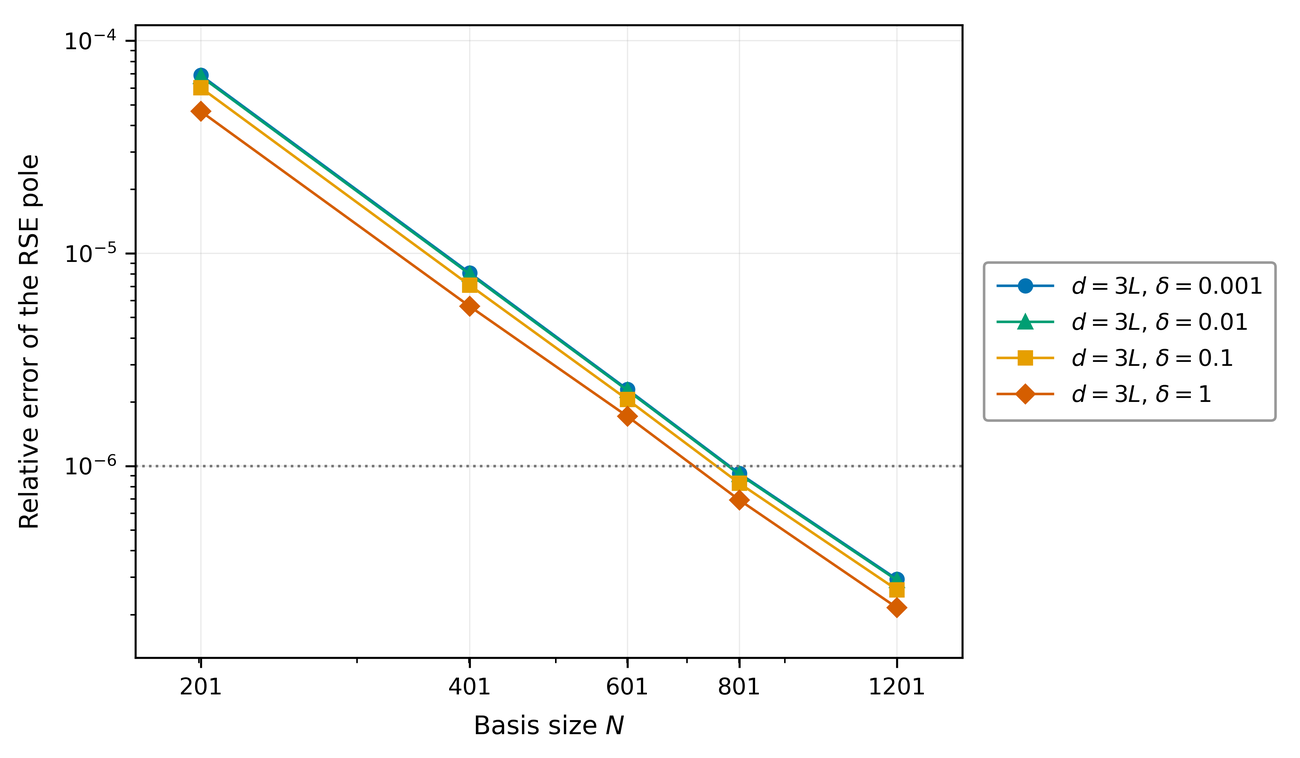

In [21]:
hardest = best.nlargest(4, "error_401")
t0 = time.time()
rows = []
for row in hardest.itertuples():
    k_ex = exact_rse[(row.d, row.delta)]
    a, pieces = rse_pieces(row.d, row.delta, row.margin, EPS_BASIS[row.basis])
    for n_basis in (201, 401, 601, 801, 1201):
        k_rse = nearest(rse_wavenumbers((n_basis - 1) // 2, EPS_BASIS[row.basis], a, pieces), k_ex)
        rows.append({"d": row.d, "delta": row.delta, "margin": row.margin, "basis": row.basis, "N": n_basis,
                     "rel_error": abs(k_rse - k_ex) / abs(k_ex)})
rse_deep = pd.DataFrame(rows)
rse_deep.to_csv(RESULTS / "rse_deep.csv", index=False)
print(f"deep truncation in {time.time() - t0:.1f} s")
first_n = rse_deep[rse_deep.rel_error < 1e-6].groupby(["d", "delta"]).N.min()
summary["rse_deep"] = {"worst_401": float(rse_deep[rse_deep.N == 401].rel_error.max()),
                       "worst_1201": float(rse_deep[rse_deep.N == 1201].rel_error.max()),
                       "all_below_1e-6_at_1201": bool((rse_deep[rse_deep.N == 1201].rel_error < 1e-6).all()),
                       "first_N_below_1e-6": {f"d = {d:g}, delta = {delta:g}": int(n) for (d, delta), n in first_n.items()},
                       "N_for_target_all_cases": int(first_n.max()) if len(first_n) == len(hardest) else None,
                       "gaps": sorted({float(r.d) for r in hardest.itertuples()}),
                       "cases": [{"d": r.d, "delta": r.delta, "margin": r.margin, "basis": r.basis} for r in hardest.itertuples()]}
print(json.dumps(summary["rse_deep"], indent=1))

fig, ax = P.new_figure(legend=True)
for (key, h), color, marker in zip(rse_deep.groupby(["d", "delta"]), (C["blue"], C["green"], C["orange"], C["vermillion"]), "o^sD"):
    ax.loglog(h.N, h.rel_error, marker + "-", color=color, ms=5, lw=1.0,
              label=rf"$d = {key[0]:g}L$, $\delta = {key[1]:g}$")
ax.axhline(1e-6, color=C["grey"], lw=1.0, ls=":")
P.log_ticks(ax, "x", [201, 401, 601, 801, 1201])
P.label(ax, r"Basis size $N$", "Relative error of the RSE pole")
P.legend_outside(fig, ax)
deep_gaps = ", ".join(f"{d:g}" for d in summary["rse_deep"]["gaps"])
publish(fig, 21, "rse_deep", "results/rse_deep.csv",
        rf"Deep truncation of the RSE for the four configurations with the largest error at $N = 401$, all at "
        rf"$d = {deep_gaps}\,L$. The dotted line marks the target relative error of $10^{{-6}}$, which every "
        rf"configuration reaches from $N = {summary['rse_deep']['N_for_target_all_cases']}$.")

## 17. Summary of results

The table below collects, for each estimator, what it needs, its measured accuracy on the production grid and the law that governs its error. All numbers in the manuscript are taken from `results/summary.json`, written by the last cell together with the figure index `figures/manifest.csv`.

In [22]:
el, maps_summary = summary["error_laws"], summary["maps"]
table = pd.DataFrame([
    {"scheme": "naive first order", "input": "overlap F(k0)", "second-order residual": "a(d) F^2",
     "cells below 10%": maps_summary["fraction_error_below_10pct"]["naive"], "error at d = 30, delta = 1e-3": el["errors_delta_1e-3_d_max"]["naive"]},
    {"scheme": "regularized first order", "input": "overlap F(Re k0)", "second-order residual": "floor |1 - c exp(-gamma_f d)|",
     "cells below 10%": maps_summary["fraction_error_below_10pct"]["reg"], "error at d = 30, delta = 1e-3": el["errors_delta_1e-3_d_max"]["reg"]},
    {"scheme": "self-consistent", "input": "overlap at k0 + dk", "second-order residual": "(alpha + b e) F^2",
     "cells below 10%": maps_summary["fraction_error_below_10pct"]["sc"], "error at d = 30, delta = 1e-3": el["errors_delta_1e-3_d_max"]["sc"]},
    {"scheme": "resummed", "input": "overlap at k0 + dk, alpha", "second-order residual": "b e F^2 (d-independent relative)",
     "cells below 10%": maps_summary["fraction_error_below_10pct"]["res"], "error at d = 30, delta = 1e-3": el["errors_delta_1e-3_d_max"]["res"]},
    {"scheme": "resummed, alpha = i/gamma_0", "input": "overlap at k0 + dk, Q", "second-order residual": "(alpha - i/gamma_0 + b e) F^2",
     "cells below 10%": maps_summary["fraction_error_below_10pct"]["res_cm"], "error at d = 30, delta = 1e-3": el["errors_delta_1e-3_d_max"]["res_cm"]},
    {"scheme": "resummed, second Born", "input": "layer reflection to 2nd order, alpha", "second-order residual": "none (third order)",
     "cells below 10%": maps_summary["fraction_error_below_10pct"]["res2"], "error at d = 30, delta = 1e-3": el["errors_delta_1e-3_d_max"]["res2"]}])
table.to_csv(RESULTS / "scheme_summary.csv", index=False)
display(table)

headline = {
    "exact growth rate (mu = 4, delta = 1e-4), 1/L": f"{summary['exact_growth']['4']['rate']:.4f} +/- {summary['exact_growth']['4']['sigma']:.4f}",
    "field rate gamma_f, 1/L": f"{GAMMA_F:.4f}",
    "naive error rate / 2 gamma_f, exact prefactor |a(d)| (mu = 4, delta = 1e-4)": f"{rates[(rates.delta == 1e-4) & (rates['mode'] == MU)].corrected_over_2gamma_f.iloc[0]:.4f}",
    "naive error rate / 2 gamma_f, propagation term 2 n_B d only": f"{summary['linear_prefactor']['rate_over_2gamma_f']:.3f}",
    "second-order coefficient, max relative deviation (40 digits)": f"{summary['mechanism_40digit']['max_rel_dev']:.1e}",
    "regularized floor law, max deviation": f"{summary['floor']['ratio_max_abs_dev']:.3f}",
    "resummed error per unit delta (predicted)": f"{KAPPA_RES:.3f}",
    "resummed error at delta = 1e-3, range over gaps": f"{el['resummed_error_delta_1e-3']['min']:.2e} to {el['resummed_error_delta_1e-3']['max']:.2e}",
    "self-consistent gain, median for d >= 8L": f"{el['gain_far']['sc']['median']:.2f}",
    "resummed gain, median for d >= 8L": f"{el['gain_far']['res']['median']:.1f}",
    "Lorentzian fits rejected": f"{summary['lorentzian']['rejected']} of {summary['lorentzian']['fits']}",
    "RSE worst error at N = 401 / N = 1201": f"{summary['rse_deep']['worst_401']:.1e} / {summary['rse_deep']['worst_1201']:.1e}",
    "RSE target 1e-6: largest gap met at N = 401 / basis size for the hardest cases": f"{summary['rse']['largest_gap_target_met_401']:g} L / {summary['rse_deep']['N_for_target_all_cases']}",
}
display(pd.Series(headline, name="value").to_frame())

summary["runtime_s"] = time.time() - T_START
pd.DataFrame(manifest).to_csv(FIGURES / "manifest.csv", index=False)


def plain(value):
    if isinstance(value, dict):
        return {str(k): plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [plain(v) for v in value]
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, complex):
        return [value.real, value.imag]
    return value


with open(RESULTS / "summary.json", "w") as fh:
    json.dump(plain(summary), fh, indent=1)
print(f"figures written: {len(manifest)}; total runtime {summary['runtime_s']:.0f} s")

,scheme,input,second-order residual,cells below 10%,"error at d = 30, delta = 1e-3"
0,naive first order,overlap F(k0),a(d) F^2,0.47378,0.36800
1,regularized first order,overlap F(Re k0),floor |1 - c exp(-gamma_f d)|,0.11888,0.96356
2,self-consistent,overlap at k0 + dk,(alpha + b e) F^2,0.51573,0.10653
3,resummed,"overlap at k0 + dk, alpha",b e F^2 (d-independent relative),0.62937,0.00399
4,"resummed, alpha = i/gamma_0","overlap at k0 + dk, Q",(alpha - i/gamma_0 + b e) F^2,0.62413,0.00163
5,"resummed, second Born","layer reflection to 2nd order, alpha",none (third order),0.73077,0.00037


,value
"exact growth rate (mu = 4, delta = 1e-4), 1/L",0.1029 +/- 0.0004
"field rate gamma_f, 1/L",0.1022
"naive error rate / 2 gamma_f, exact prefactor |a(d)| (mu = 4, delta = 1e-4)",1.0054
"naive error rate / 2 gamma_f, propagation term 2 n_B d only",0.892
"second-order coefficient, max relative deviation (40 digits)",5.0e-07
"regularized floor law, max deviation",0.028
resummed error per unit delta (predicted),3.864
"resummed error at delta = 1e-3, range over gaps",3.36e-03 to 5.49e-03
"self-consistent gain, median for d >= 8L",2.82
"resummed gain, median for d >= 8L",20.5


figures written: 21; total runtime 100 s
